In [ ]:
from google.colab import userdata
hf_token = userdata.get('HF_TOKEN')

from huggingface_hub import HfApi
api = HfApi(token=hf_token)

#kiểm tra dữ liệu

In [ ]:
#check data embindex
final_embeddings = np.load(hidden_path)
final_keys_df = pd.read_parquet(keys_path)
assert final_embeddings.shape[0] == len(final_keys_df), \
    f"LỆCH SỐ DÒNG: embeddings={final_embeddings.shape[0]} vs keys={len(final_keys_df)}"
print("✅ Số dòng khớp nhau")

✅ Số dòng khớp nhau


In [ ]:
# check duplicate key
dup = final_keys_df.duplicated(subset=['signal_family', 'signalid', 'oos_begin_year']).sum()
print(f"Số dòng key bị trùng lặp: {dup}")
assert dup == 0, f"Có {dup} dòng key bị trùng lặp — cần điều tra nguồn gốc (resume bị lỗi?)"
print("✅ Không có key trùng lặp")

Số dòng key bị trùng lặp: 0
✅ Không có key trùng lặp


In [ ]:
# check alignment bằng cosine similarity
sig_check = final_keys_df.groupby(['signal_family', 'signalid']).filter(lambda x: len(x) >= 2)
sample = sig_check.sort_values(['signal_family', 'signalid', 'oos_begin_year'])
first_sig = sample.iloc[0]
same_sig_rows = sample[
    (sample['signal_family'] == first_sig['signal_family']) &
    (sample['signalid'] == first_sig['signalid'])
].sort_values('oos_begin_year')

print("2 dòng cùng signal, năm liên tiếp:")
print(same_sig_rows[['signal_family', 'signalid', 'oos_begin_year']].head(2))

pos = same_sig_rows.index[:2].tolist()
e1 = np.asarray(final_embeddings[pos[0]])
e2 = np.asarray(final_embeddings[pos[1]])

if e1.ndim > 1:
    e1_flat, e2_flat = e1.mean(axis=0), e2.mean(axis=0)
else:
    e1_flat, e2_flat = e1, e2

cos_sim_same = np.dot(e1_flat, e2_flat) / (np.linalg.norm(e1_flat) * np.linalg.norm(e2_flat))
print(f"\nCosine similarity — CÙNG signal, 2 năm liên tiếp: {cos_sim_same:.4f}")

diff_sig_rows = final_keys_df[
    (final_keys_df['oos_begin_year'] == first_sig['oos_begin_year']) &
    (final_keys_df['signalid'] != first_sig['signalid'])
]
if len(diff_sig_rows) > 0:
    pos_diff = diff_sig_rows.index[0]
    e3 = np.asarray(final_embeddings[pos_diff])
    e3_flat = e3.mean(axis=0) if e3.ndim > 1 else e3
    cos_sim_diff = np.dot(e1_flat, e3_flat) / (np.linalg.norm(e1_flat) * np.linalg.norm(e3_flat))
    print(f"Cosine similarity — KHÁC signal, cùng năm: {cos_sim_diff:.4f}")
    print(f"\n→ cos_sim_same nên CAO HƠN RÕ RỆT cos_sim_diff nếu alignment đúng.")
else:
    print("Không tìm được signal khác để đối chứng ở năm này.")

2 dòng cùng signal, năm liên tiếp:
                 signal_family signalid  oos_begin_year
0  DataMinedLongShortReturnsEW        1            1994
1  DataMinedLongShortReturnsEW        1            1995

Cosine similarity — CÙNG signal, 2 năm liên tiếp: 0.8132
Cosine similarity — KHÁC signal, cùng năm: 0.9860

→ cos_sim_same nên CAO HƠN RÕ RỆT cos_sim_diff nếu alignment đúng.


In [ ]:
# Lấy 1 mẫu ngẫu nhiên nhiều embedding để tính "mean vector chung" (anisotropic direction)
np.random.seed(0)
sample_idx = np.random.choice(len(final_embeddings), size=min(2000, len(final_embeddings)), replace=False)
sample_flat = np.array([
    np.asarray(final_embeddings[i]).mean(axis=0) if np.asarray(final_embeddings[i]).ndim > 1
    else np.asarray(final_embeddings[i])
    for i in sample_idx
])
global_mean = sample_flat.mean(axis=0)

def cos_sim_centered(a, b, global_mean):
    a_c = a - global_mean
    b_c = b - global_mean
    return np.dot(a_c, b_c) / (np.linalg.norm(a_c) * np.linalg.norm(b_c))

cos_sim_same_c = cos_sim_centered(e1_flat, e2_flat, global_mean)
cos_sim_diff_c = cos_sim_centered(e1_flat, e3_flat, global_mean)
print(f"Cosine similarity (đã trừ mean chung) — CÙNG signal: {cos_sim_same_c:.4f}")
print(f"Cosine similarity (đã trừ mean chung) — KHÁC signal: {cos_sim_diff_c:.4f}")

Cosine similarity (đã trừ mean chung) — CÙNG signal: 0.6513
Cosine similarity (đã trừ mean chung) — KHÁC signal: 0.9747


In [ ]:
import random
random.seed(0)

def get_flat(pos):
    e = np.asarray(final_embeddings[pos])
    return e.mean(axis=0) if e.ndim > 1 else e

# lấy N signal có >= 2 năm liên tiếp
groups = final_keys_df.groupby(['signal_family', 'signalid'])
multi_year_signals = [g for _, g in groups if len(g) >= 2]
random.shuffle(multi_year_signals)

same_sims, diff_sims = [], []
n_pairs = 100

for g in multi_year_signals[:n_pairs]:
    g_sorted = g.sort_values('oos_begin_year')
    pos1, pos2 = g_sorted.index[0], g_sorted.index[1]
    e_a, e_b = get_flat(pos1), get_flat(pos2)
    sim = np.dot(e_a, e_b) / (np.linalg.norm(e_a) * np.linalg.norm(e_b))
    same_sims.append(sim)

    # random pair khác signal, khác vị trí bất kỳ
    rand_pos = random.choice(final_keys_df.index.tolist())
    while rand_pos in (pos1, pos2):
        rand_pos = random.choice(final_keys_df.index.tolist())
    e_r = get_flat(rand_pos)
    sim_diff = np.dot(e_a, e_r) / (np.linalg.norm(e_a) * np.linalg.norm(e_r))
    diff_sims.append(sim_diff)

same_sims = np.array(same_sims)
diff_sims = np.array(diff_sims)

print(f"Cùng signal (liên tiếp năm), n={len(same_sims)}: mean={same_sims.mean():.4f}, std={same_sims.std():.4f}")
print(f"Khác signal (ngẫu nhiên),   n={len(diff_sims)}: mean={diff_sims.mean():.4f}, std={diff_sims.std():.4f}")

from scipy import stats
tstat, pval = stats.ttest_ind(same_sims, diff_sims)
print(f"\nt-test: t={tstat:.3f}, p={pval:.4g}")
print("→ Nếu same_sims.mean() KHÔNG cao hơn diff_sims.mean() một cách có ý nghĩa thống kê (p<0.05), "
      "cần nghi ngờ nghiêm túc về alignment.")

Cùng signal (liên tiếp năm), n=100: mean=0.8486, std=0.0768
Khác signal (ngẫu nhiên),   n=100: mean=0.6789, std=0.1744

t-test: t=8.857, p=4.684e-16
→ Nếu same_sims.mean() KHÔNG cao hơn diff_sims.mean() một cách có ý nghĩa thống kê (p<0.05), cần nghi ngờ nghiêm túc về alignment.


In [ ]:
# Với 1 vài signal, tính vài thống kê đơn giản của input ts (mean, std, last value)
# rồi xem embedding có "phản ánh" đúng các signal khác nhau hay không, bằng cách
# train 1 classifier/probe đơn giản: dự đoán signalid từ embedding.
# Nếu accuracy rất thấp (gần random), embedding có thể không phân biệt được các signal
# -> nghi ngờ cả alignment lẫn chất lượng embedding.

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# lấy 1 subset nhỏ, ví dụ 20 signal khác nhau, mỗi signal lấy embedding ở 1 năm cố định
sub_keys = final_keys_df[final_keys_df['oos_begin_year'] == 2000]
sub_keys = sub_keys.groupby('signalid').first().reset_index()
if len(sub_keys) > 20:
    sub_keys = sub_keys.sample(20, random_state=0)

X = np.array([get_flat(i) for i in sub_keys.index])
y = sub_keys['signalid'].values

if len(np.unique(y)) > 1 and len(X) > 10:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)
    clf = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    acc = clf.score(X_te, y_te)
    print(f"Probe accuracy (dự đoán signalid từ embedding): {acc:.3f} "
          f"(random baseline ≈ {1/len(np.unique(y)):.3f})")

Probe accuracy (dự đoán signalid từ embedding): 0.000 (random baseline ≈ 0.050)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# chọn các signal có >= 4 năm dữ liệu, lấy 10-15 signal, MỖI signal lấy NHIỀU năm
groups = final_keys_df.groupby('signalid').filter(lambda x: len(x) >= 4)
chosen_sids = groups['signalid'].drop_duplicates().sample(15, random_state=0)
sub_keys = groups[groups['signalid'].isin(chosen_sids)]

X = np.array([get_flat(i) for i in sub_keys.index])
y = sub_keys['signalid'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
clf = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
acc = clf.score(X_te, y_te)
print(f"Probe accuracy: {acc:.3f} (random baseline ≈ {1/len(np.unique(y)):.3f}, n_classes={len(np.unique(y))})")

Probe accuracy: 0.203 (random baseline ≈ 0.067, n_classes=15)


# training fincast lstm att - ACCT EW

In [ ]:
#fincast+lstm+att
import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr
from huggingface_hub import hf_hub_download

# ============================================================
# 0. Config — CHỈ 1 FAMILY
# ============================================================
FAMILY = 'DataMinedLongShortReturnsEW'
KEYS_DIR = '/content/fincast_embeddings'
REPO_ID = "ngandh/fincast-embeddings"
REPO_TYPE = "dataset"

rollsignal_path = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
ROLLSIGNAL_USECOLS = ['signalid', 'signal_family', 's_flag', 'oos_begin_year', 'tstat', 'mean_ret']
RESULTS_DIR = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_onlyAcctEW'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Mốc năm cố định — PHẢI KHỚP với bản train_lstm_no_fincast (raw LSTM) để so sánh công bằng
VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014

# ============================================================
# 1. Tải hidden (.npy) + keys (.parquet) cho ĐÚNG 1 family
# ============================================================
hidden_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=f"fincast_hidden_{FAMILY}.npy",
    repo_type=REPO_TYPE,
    token=hf_token,
)
keys_path = '/content/fincast_keys_DataMinedLongShortReturnsEW.parquet'
assert os.path.exists(keys_path), f"Không tìm thấy {keys_path}"

print(f"hidden_path: {hidden_path}")
print(f"keys_path:   {keys_path}")

hidden_arr = np.load(hidden_path, mmap_mode='r')   # KHÔNG load hết vào RAM
print("hidden_arr shape:", hidden_arr.shape)

hidden_path: /root/.cache/huggingface/hub/datasets--ngandh--fincast-embeddings/snapshots/2214269a23d64b63c1db6536540f1f20bd13af89/fincast_hidden_DataMinedLongShortReturnsEW.npy
keys_path:   /content/fincast_keys_DataMinedLongShortReturnsEW.parquet
hidden_arr shape: (1033883, 4, 1280)


In [ ]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr

# ============================================================
# 0. Reproducibility — FIX #4
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ============================================================
# 2. Merge rollsignal (IS/OOS) với keys — CHỈ 1 FAMILY
# ============================================================
# ============================================================
# 2. Merge rollsignal (IS/OOS) với keys — CHỈ 1 FAMILY
# ============================================================
def join_rollsignal_with_sequence(rollsignal_path, keys_path):
    rollsignal = pd.read_csv(rollsignal_path, usecols=ROLLSIGNAL_USECOLS)
    rollsignal['signalid'] = rollsignal['signalid'].astype(str)
    rollsignal['tstat'] = rollsignal['tstat'].astype(np.float32)
    rollsignal['mean_ret'] = rollsignal['mean_ret'].astype(np.float32)

    is_df = rollsignal[rollsignal['s_flag'] == 'IS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'tstat', 'mean_ret']
    ].rename(columns={'tstat': 'tstat_IS', 'mean_ret': 'mean_ret_IS'})

    oos_df = rollsignal[rollsignal['s_flag'] == 'OOS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'mean_ret']
    ].rename(columns={'mean_ret': 'mean_ret_OOS'})

    del rollsignal
    gc.collect()

    keys_df = pd.read_parquet(keys_path)
    keys_df['signalid'] = keys_df['signalid'].astype(str)
    if 'emb_idx' not in keys_df.columns:
        keys_df['emb_idx'] = np.arange(len(keys_df), dtype=np.int32)

    # assert unique key/emb_idx trước khi merge
    dup_keys = keys_df.duplicated(subset=['signalid', 'signal_family', 'oos_begin_year']).sum()
    assert dup_keys == 0, f"keys_df có {dup_keys} dòng key bị trùng lặp — kiểm tra lại file extraction"
    assert keys_df['emb_idx'].is_unique, "emb_idx trong keys_df không unique"

    # ---- CHẨN ĐOÁN trước khi merge, giúp biết 19.2% do đâu ----
    fam = keys_df['signal_family'].iloc[0] if len(keys_df) > 0 else None
    is_df_fam = is_df[is_df['signal_family'] == fam] if fam else is_df
    print(f"[Chẩn đoán] Family trong keys_df: {sorted(keys_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Family trong is_df (rollsignal, IS): {sorted(is_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): {len(is_df_fam)}")
    print(f"[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    {len(keys_df)}")
    print(f"[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: "
          f"{len(keys_df) / max(len(is_df_fam), 1) * 100:.1f}%")

    is_df = is_df.merge(
        keys_df[['signalid', 'signal_family', 'oos_begin_year', 'emb_idx']],
        on=['signalid', 'signal_family', 'oos_begin_year'], how='left'
    )
    n_matched = is_df['emb_idx'].notna().sum()
    print(f"Matched: {n_matched}/{len(is_df)} ({n_matched/len(is_df)*100:.1f}%)")

    del keys_df
    gc.collect()
    return is_df, oos_df


is_df, oos_df = join_rollsignal_with_sequence(rollsignal_path, keys_path)
merged = is_df.merge(oos_df, on=['signalid', 'signal_family', 'oos_begin_year'], how='inner')
del is_df, oos_df
gc.collect()

merged = merged.dropna(subset=['emb_idx', 'tstat_IS', 'mean_ret_IS', 'mean_ret_OOS'])
merged['emb_idx'] = merged['emb_idx'].astype(np.int32)

# FIX #3: assert unique emb_idx trong merged (mỗi signal-window chỉ map đúng 1 embedding)
dup_merged = merged['emb_idx'].duplicated().sum()
assert dup_merged == 0, f"merged có {dup_merged} dòng emb_idx bị trùng lặp — kiểm tra lại merge key"

print("Số signal-window:", len(merged))
print(merged['signal_family'].value_counts())


# ============================================================
# 3. Model, metrics, batch iterator (streaming)
# ============================================================
class LSTMAttentionRegressor(nn.Module):
    def __init__(self, seq_input_dim=1280, extra_feat_dim=2, lstm_hidden=128, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=seq_input_dim, hidden_size=lstm_hidden, num_layers=1,
            batch_first=True, bidirectional=True,
        )
        lstm_out_dim = lstm_hidden * 2
        self.attn_proj = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_v = nn.Linear(lstm_out_dim, 1, bias=False)
        head_in = lstm_out_dim + extra_feat_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, seq, extra_feats):
        lstm_out, _ = self.lstm(seq)
        scores = self.attn_v(torch.tanh(self.attn_proj(lstm_out))).squeeze(-1)
        attn_weights = torch.softmax(scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1)
        combined = torch.cat([context, extra_feats], dim=1)
        pred = self.head(combined).squeeze(-1)
        return pred, attn_weights


def compute_scaler_stats_streaming(hidden_arr, idx_array, batch_size=50000):
    """
    FIX #1: chỉ tính mean/std trên idx_array (phải truyền idx_train),
    tránh leak thông tin phân phối của val/test vào bước chuẩn hoá.
    """
    D = hidden_arr.shape[2]
    sum_ = np.zeros(D, dtype=np.float64)
    sum_sq = np.zeros(D, dtype=np.float64)
    count = 0
    n = len(idx_array)
    idx_sorted = np.sort(idx_array)
    for i in range(0, n, batch_size):
        batch_idx = idx_sorted[i:i+batch_size]
        chunk = np.asarray(hidden_arr[batch_idx]).reshape(-1, D)
        sum_ += chunk.sum(axis=0)
        sum_sq += (chunk.astype(np.float64) ** 2).sum(axis=0)
        count += chunk.shape[0]
    mean = sum_ / count
    std = np.sqrt(sum_sq / count - mean ** 2)
    return mean.astype(np.float32), std.astype(np.float32)


def iterate_batches_streaming(idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                               batch_size, shuffle=True, device='cuda'):
    """
    Dùng cho TRAIN và VALIDATION. Bên trong mỗi batch dữ liệu bị sort lại theo
    emb_id tăng dần (đọc mmap nhanh hơn), nhưng seq_b/feat_b/yb luôn được áp
    permutation ĐỒNG BỘ nên khi lấy yb trực tiếp từ generator này, thứ tự luôn khớp.
    """
    n = len(idx_array)
    order = np.random.permutation(n) if shuffle else np.arange(n)
    for start in range(0, n, batch_size):
        batch_order = order[start:start + batch_size]
        emb_ids = idx_array[batch_order]
        sort_order = np.argsort(emb_ids)
        emb_ids_sorted = emb_ids[sort_order]
        seq_b = np.asarray(hidden_arr[emb_ids_sorted])
        seq_b = (seq_b - mean_) / (std_ + 1e-8)
        seq_b = torch.from_numpy(seq_b.astype(np.float32))
        feat_b = torch.from_numpy(feat_arr[batch_order][sort_order].astype(np.float32))
        yb = torch.from_numpy(y_arr[batch_order][sort_order].astype(np.float32))
        if device != 'cpu':
            seq_b = seq_b.to(device, non_blocking=True)
            feat_b = feat_b.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
        yield seq_b, feat_b, yb


def eval_streaming_ordered(model, idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                            batch_size, device):
    """
    FIX #2: dùng cho eval CUỐI CÙNG trên test set.
    iterate_batches_streaming sort lại thứ tự BÊN TRONG mỗi batch theo emb_id.
    Nếu ghép các batch pred lại rồi so với y_test GIỮ NGUYÊN THỨ TỰ GỐC, cặp
    (pred, true) sẽ lệch hàng. Hàm này tự trả lại y_true/idx đã permute đúng
    theo cách model đã predict, đảm bảo pred[i] luôn khớp true[i] và idx[i].
    """
    model.eval()
    all_pred, all_true, all_idx = [], [], []
    n = len(idx_array)
    order = np.arange(n)
    with torch.no_grad():
        for start in range(0, n, batch_size):
            batch_order = order[start:start + batch_size]
            emb_ids = idx_array[batch_order]
            sort_order = np.argsort(emb_ids)
            emb_ids_sorted = emb_ids[sort_order]

            seq_b = np.asarray(hidden_arr[emb_ids_sorted])
            seq_b = (seq_b - mean_) / (std_ + 1e-8)
            seq_b = torch.from_numpy(seq_b.astype(np.float32)).to(device)

            feat_b = torch.from_numpy(
                feat_arr[batch_order][sort_order].astype(np.float32)
            ).to(device)
            y_b = y_arr[batch_order][sort_order]

            pred_b, _ = model(seq_b, feat_b)

            all_pred.append(pred_b.cpu().numpy())
            all_true.append(y_b)
            all_idx.append(emb_ids_sorted)

    pred_final = np.concatenate(all_pred)
    y_final = np.concatenate(all_true)
    idx_final = np.concatenate(all_idx)
    return pred_final, y_final, idx_final


def compute_regression_metrics(y_true, y_pred, prefix=''):
    y_true_sign = (y_true > 0).astype(int)
    y_pred_sign = (y_pred > 0).astype(int)
    return {
        f'{prefix}mse': float(np.mean((y_pred - y_true) ** 2)),
        f'{prefix}mae': float(mean_absolute_error(y_true, y_pred)),
        f'{prefix}r2': float(r2_score(y_true, y_pred)),
        f'{prefix}dir_acc': float(accuracy_score(y_true_sign, y_pred_sign)),
        f'{prefix}precision': float(precision_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}recall': float(recall_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}f1': float(f1_score(y_true_sign, y_pred_sign, zero_division=0)),
    }


def portfolio_relevant_report_yearly(y_true, y_pred, oos_years, n_deciles=10):
    """
    FIX #5: rank theo TỪNG NĂM riêng biệt (đúng logic portfolio formation của
    High-Throughput), sau đó aggregate — thay vì rank pooled toàn bộ test 2014-2021.
    """
    df = pd.DataFrame({'year': oos_years, 'y_true': y_true, 'y_pred': y_pred})

    # IC theo từng năm, rồi lấy trung bình (time-series average IC)
    ic_rows = []
    for yr, g in df.groupby('year'):
        if len(g) < 5:
            continue
        ic_yr, _ = spearmanr(g['y_pred'], g['y_true'])
        ic_rows.append({'oos_begin_year': yr, 'n': len(g), 'IC': ic_yr})
    ic_by_year_df = pd.DataFrame(ic_rows).sort_values('oos_begin_year')
    ic_mean = ic_by_year_df['IC'].mean()
    ic_std = ic_by_year_df['IC'].std()
    print(f"\nMean yearly IC: {ic_mean:.4f} (std={ic_std:.4f}, n_years={len(ic_by_year_df)})")
    print(ic_by_year_df.to_string(index=False))

    # Decile rank TRONG TỪNG NĂM, không pool
    decile_rows = []
    for yr, g in df.groupby('year'):
        g = g.copy()
        try:
            g['decile'] = pd.qcut(g['y_pred'], n_deciles, labels=np.arange(1, n_deciles + 1))
        except ValueError:
            continue  # không đủ unique values để chia n_deciles nhóm
        for d, sub in g.groupby('decile', observed=True):
            decile_rows.append({
                'year': yr, 'decile': int(d), 'n': len(sub),
                'mean_pred': sub['y_pred'].mean(),
                'mean_actual_ret': sub['y_true'].mean(),
            })
    decile_by_year_df = pd.DataFrame(decile_rows)

    decile_agg = decile_by_year_df.groupby('decile').agg(
        n=('n', 'sum'),
        mean_pred=('mean_pred', 'mean'),
        mean_actual_ret=('mean_actual_ret', 'mean'),
    ).reset_index()
    print("\nDecile spread (trung bình các năm, KHÔNG pooled):")
    print(decile_agg.to_string(index=False))

    is_monotonic = decile_agg['mean_actual_ret'].is_monotonic_increasing

    # long-short spread: tính theo TỪNG NĂM rồi lấy trung bình + t-stat
    ls_by_year = decile_by_year_df.pivot(index='year', columns='decile', values='mean_actual_ret')
    ls_spread_by_year = ls_by_year[n_deciles] - ls_by_year[1]
    ls_spread_mean = ls_spread_by_year.mean()
    ls_spread_tstat = ls_spread_mean / ls_spread_by_year.std() * np.sqrt(len(ls_spread_by_year))
    print(f"\nLong-short spread (trung bình theo năm): {ls_spread_mean:.4f}, "
          f"t-stat: {ls_spread_tstat:.4f}")

    return {
        'ic_by_year': ic_by_year_df, 'ic_mean': float(ic_mean), 'ic_std': float(ic_std),
        'decile_by_year': decile_by_year_df, 'decile_agg': decile_agg,
        'is_monotonic': bool(is_monotonic),
        'long_short_spread_by_year': ls_spread_by_year,
        'long_short_spread_mean': float(ls_spread_mean),
        'long_short_spread_tstat': float(ls_spread_tstat),
    }


# ============================================================
# 4. Train + eval streaming — train/val/test theo MỐC NĂM CỐ ĐỊNH
# ============================================================
def train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100, lr=1e-3, seed=42,
    val_year_cutoff=VAL_YEAR_CUTOFF, test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path='training_log.csv',
    eval_every=5, batch_size=1024, device=None,
    early_stopping_patience=15,
    checkpoint_dir=None, checkpoint_every=5,
    scaler_batch_size=50000,
):
    """
    Split theo mốc năm cố định (khớp với bản LSTM raw train_lstm_no_fincast):
      - train: oos_begin_year <  val_year_cutoff
      - val  : val_year_cutoff <= oos_begin_year < test_year_cutoff  (early-stop/chọn checkpoint)
      - test : oos_begin_year >= test_year_cutoff                    (chỉ eval cuối, không leak)
    """
    set_seed(seed)  # FIX #4: re-seed ngay đầu hàm train để đảm bảo reproducible dù gọi lại nhiều lần

    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Device: {device}, batch_size={batch_size}")

    emb_idx_all = merged['emb_idx'].to_numpy(dtype=np.int64)
    extra_feats_all = merged[['tstat_IS', 'mean_ret_IS']].to_numpy(dtype=np.float32)
    y_ret = merged['mean_ret_OOS'].to_numpy(dtype=np.float32)
    years_all = merged['oos_begin_year'].to_numpy()

    train_mask = years_all < val_year_cutoff
    val_mask   = (years_all >= val_year_cutoff) & (years_all < test_year_cutoff)
    test_mask  = years_all >= test_year_cutoff

    assert train_mask.sum() > 0, "Train set rỗng, kiểm tra lại val_year_cutoff"
    assert val_mask.sum()   > 0, "Validation set rỗng, kiểm tra lại val_year_cutoff/test_year_cutoff"
    assert test_mask.sum()  > 0, "Test set rỗng, kiểm tra lại test_year_cutoff"

    print(f"Split theo năm CỐ ĐỊNH: train < {val_year_cutoff} (n={train_mask.sum()}), "
          f"val [{val_year_cutoff}, {test_year_cutoff}) (n={val_mask.sum()}), "
          f"test >= {test_year_cutoff} (n={test_mask.sum()})")

    idx_train, idx_val, idx_test = emb_idx_all[train_mask], emb_idx_all[val_mask], emb_idx_all[test_mask]
    feat_train, feat_val, feat_test = extra_feats_all[train_mask], extra_feats_all[val_mask], extra_feats_all[test_mask]
    y_train, y_val, y_test = y_ret[train_mask], y_ret[val_mask], y_ret[test_mask]
    years_train, years_val, years_test = years_all[train_mask], years_all[val_mask], years_all[test_mask]

    del emb_idx_all, extra_feats_all, y_ret, years_all
    gc.collect()

    # ---- FIX #1: scaler fit CHỈ trên train ----
    print("Đang tính mean/std của embedding (streaming, CHỈ trên train)...")
    mean_, std_ = compute_scaler_stats_streaming(hidden_arr, idx_train, batch_size=scaler_batch_size)

    feat_scaler = StandardScaler(copy=False)
    feat_train = feat_scaler.fit_transform(feat_train).astype(np.float32)
    feat_val   = feat_scaler.transform(feat_val).astype(np.float32)
    feat_test  = feat_scaler.transform(feat_test).astype(np.float32)

    D = hidden_arr.shape[2]
    model = LSTMAttentionRegressor(seq_input_dim=D, extra_feat_dim=feat_train.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    if checkpoint_dir is not None:
        os.makedirs(checkpoint_dir, exist_ok=True)
    best_ckpt_path = f'{checkpoint_dir}/best.pt' if checkpoint_dir else None
    last_ckpt_path = f'{checkpoint_dir}/last.pt' if checkpoint_dir else None

    history = []
    best_val_ic = -float('inf')
    best_state = None
    epochs_no_improve = 0

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss_sum, n_seen = 0.0, 0
        for seq_b, feat_b, yb in iterate_batches_streaming(
            idx_train, feat_train, y_train, hidden_arr, mean_, std_,
            batch_size=batch_size, shuffle=True, device=device,
        ):
            optimizer.zero_grad()
            pred, _ = model(seq_b, feat_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        train_mse_running = train_loss_sum / max(n_seen, 1)

        do_eval = (epoch + 1) % eval_every == 0 or epoch == epochs - 1
        if do_eval:
            model.eval()
            val_preds, val_trues = [], []
            with torch.no_grad():
                for seq_b, feat_b, yb in iterate_batches_streaming(
                    idx_val, feat_val, y_val, hidden_arr, mean_, std_,
                    batch_size=batch_size, shuffle=False, device=device,
                ):
                    pred, _ = model(seq_b, feat_b)
                    val_preds.append(pred.cpu().numpy())
                    val_trues.append(yb.cpu().numpy())
            val_pred_arr = np.concatenate(val_preds)
            val_true_arr = np.concatenate(val_trues)
            val_metrics = compute_regression_metrics(val_true_arr, val_pred_arr, prefix='val_')
            val_ic, _ = spearmanr(val_pred_arr, val_true_arr)
            val_ic = float(val_ic) if not np.isnan(val_ic) else -1.0
            val_metrics['val_ic'] = val_ic

            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE: {train_mse_running:.6f} | "
                  f"Val MSE: {val_metrics['val_mse']:.6f} | Val IC: {val_ic:.4f}")
            history.append({'epoch': epoch+1, 'train_mse_running': train_mse_running, **val_metrics})

            if val_ic > best_val_ic + 1e-8:
                best_val_ic = val_ic
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_no_improve = 0
                if best_ckpt_path:
                    torch.save({'epoch': epoch+1, 'model_state': best_state, 'val_ic': best_val_ic}, best_ckpt_path)
            else:
                epochs_no_improve += eval_every
                if epochs_no_improve >= early_stopping_patience:
                    print(f"⏹ Early stopping tại epoch {epoch+1}")
                    break
        else:
            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE (running): {train_mse_running:.6f}")

        if last_ckpt_path and ((epoch+1) % checkpoint_every == 0 or epoch == epochs-1):
            torch.save({'epoch': epoch+1, 'model_state': model.state_dict(),
                        'optimizer_state': optimizer.state_dict(), 'history': history}, last_ckpt_path)

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"✅ Khôi phục best model (val_IC={best_val_ic:.4f})")

    history_df = pd.DataFrame(history)
    history_df.to_csv(log_path, index=False)

    # ---- FIX #2: eval cuối trên test, dùng hàm ordered để tránh lệch pred/true ----
    pred_nn, y_test_ordered, idx_test_ordered = eval_streaming_ordered(
        model, idx_test, feat_test, y_test, hidden_arr, mean_, std_,
        batch_size=batch_size, device=device,
    )

    # years_test phải map lại theo idx_test_ordered (không dùng years_test gốc trực tiếp,
    # vì idx_test_ordered đã bị permute so với idx_test ban đầu)
    idx_to_year = dict(zip(idx_test, years_test))
    years_test_ordered = np.array([idx_to_year[i] for i in idx_test_ordered])

    # ---- FIX #5: dùng report yearly thay vì pooled ----
    portfolio_report = portfolio_relevant_report_yearly(y_test_ordered, pred_nn, oos_years=years_test_ordered)

    results = {
        'pred_nn': pred_nn,
        'y_test': y_test_ordered,
        'years_test': years_test_ordered,
        'idx_test': idx_test_ordered,   # thứ tự ĐÃ PERMUTE, khớp 1-1 với pred_nn
        'best_val_ic': best_val_ic,
        'val_year_cutoff': val_year_cutoff,
        'test_year_cutoff': test_year_cutoff,
    }
    return model, mean_, std_, feat_scaler, results, history_df, portfolio_report


# ============================================================
# 5. Chạy train — CHỈ 1 FAMILY
# ============================================================
fam_log_path = f'{RESULTS_DIR}/log_{FAMILY}.csv'
fam_ckpt_dir = f'/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/checkpoints_{FAMILY}'

model, mean_, std_, feat_scaler, results, history_df, portfolio_report = train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100,
    batch_size=1024,
    val_year_cutoff=VAL_YEAR_CUTOFF,
    test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path=fam_log_path,
    checkpoint_dir=fam_ckpt_dir,
    early_stopping_patience=15,
)

print(f"\n✅ Best validation IC (dùng để chọn checkpoint): {results['best_val_ic']:.4f}")
print(f"✅ Mean yearly test IC (đánh giá cuối cùng, không leak, không pooled): "
      f"{portfolio_report['ic_mean']:.4f}")

# ============================================================
# 6. Lưu predictions test kèm meta — để dùng cho bước so sánh EB/Naive/LSTM
#    idx_test đã đúng thứ tự khớp với pred_nn nhờ FIX #2, nên chỉ cần join lại
#    theo emb_idx rồi sort theo vị trí trong idx_test.
# ============================================================
idx_test_ordered = results['idx_test']

# FIX #3: assert unique trước khi map, tránh nhân bản dòng khi join
test_meta = merged[merged['emb_idx'].isin(idx_test_ordered)][
    ['signal_family', 'signalid', 'oos_begin_year', 'emb_idx']
].copy()
assert test_meta['emb_idx'].is_unique, "emb_idx trong test_meta bị trùng — merge sai key"
test_meta['signalid'] = test_meta['signalid'].astype(str)

idx_to_pos = {v: i for i, v in enumerate(idx_test_ordered)}
test_meta['_pos'] = test_meta['emb_idx'].map(idx_to_pos)
test_meta = test_meta.sort_values('_pos').drop(columns=['_pos', 'emb_idx']).reset_index(drop=True)

assert len(test_meta) == len(results['pred_nn']), \
    f"Số dòng lệch: test_meta={len(test_meta)} vs pred_nn={len(results['pred_nn'])}"

test_meta['pred_ret_fincast'] = results['pred_nn']

pred_out_path = f'{RESULTS_DIR}/predictions_test_FinCast_{FAMILY}.parquet'
test_meta.to_parquet(pred_out_path, index=False)
print(f"✅ Đã lưu predictions FinCast: {pred_out_path}")
print(f"✅ Đã lưu checkpoint: {fam_ckpt_dir}/best.pt")

saved_check = pd.read_parquet(pred_out_path)
print(f"\nKiểm tra: tồn tại={os.path.exists(pred_out_path)}, shape={saved_check.shape}")

[Chẩn đoán] Family trong keys_df: ['DataMinedLongShortReturnsEW']
[Chẩn đoán] Family trong is_df (rollsignal, IS): ['DataMinedLongShortReturnsEW', 'DataMinedLongShortReturnsVW', 'PastReturnSignalsLongShort_ew', 'PastReturnSignalsLongShort_vw', 'TickerSignalsLongShort_ew', 'TickerSignalsLongShort_vw']
[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): 1005582
[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    1033883
[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: 102.8%
Matched: 979380/5113700 (19.2%)
Số signal-window: 979380
signal_family
DataMinedLongShortReturnsEW    979380
Name: count, dtype: int64
Device: cuda, batch_size=1024
Split theo năm CỐ ĐỊNH: train < 2011 (n=692447), val [2011, 2014) (n=79133), test >= 2014 (n=207800)
Đang tính mean/std của embedding (streaming, CHỈ trên train)...
Epoch 1/100 (31.8s) | Train MSE (running): 0.846007
Epoch 2/100 (30.5s) | Train MSE (running): 0.685243
Epoch 3/100 (31.5s) | Train MSE (running): 0.645686
Epoch 4/100 (31.4s

# training lstm att (no fincast)

In [ ]:
import torch
import torch.nn as nn
import random
import time
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

# ============================================================
# 0. Reproducibility — đồng bộ với bản FinCast
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ============================================================
# Config đường dẫn
# ============================================================
RESULTS_DIR_EW = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_onlyAcctEW'
FAMILY = 'DataMinedLongShortReturnsEW'
v3_ckpt_dir = f'/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/checkpoints_{FAMILY}_V3'
os.makedirs(RESULTS_DIR_EW, exist_ok=True)
os.makedirs(v3_ckpt_dir, exist_ok=True)

# Mốc năm cố định — PHẢI KHỚP với bản FinCast để so sánh công bằng
VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014

# ============================================================
# Model
# ============================================================
class LSTMAttentionRaw(nn.Module):
    def __init__(self, lookback=20, hidden_size=32, extra_feat_dim=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=1,
                             batch_first=True, bidirectional=True)
        lstm_out_dim = hidden_size * 2
        self.attn_proj = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_v = nn.Linear(lstm_out_dim, 1, bias=False)
        head_in = lstm_out_dim + extra_feat_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, seq, extra_feats):
        lstm_out, _ = self.lstm(seq)
        scores = self.attn_v(torch.tanh(self.attn_proj(lstm_out))).squeeze(-1)
        attn_weights = torch.softmax(scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1)
        combined = torch.cat([context, extra_feats], dim=1)
        return self.head(combined).squeeze(-1), attn_weights


def prepare_lookback_data(ret_panel, merged_fam, lookback=20):
    ret_panel = ret_panel.copy()
    ret_panel['year_month'] = ret_panel['date'].dt.to_period('M')
    ret_grouped = ret_panel.groupby(['signal_family', 'signalid'])
    seq_list, feat_list, y_list, meta_list = [], [], [], []
    for _, row in merged_fam.iterrows():
        fam, sid, yr = row['signal_family'], row['signalid'], row['oos_begin_year']
        is_end_period = pd.Period(year=int(yr) - 1, month=12, freq='M')
        is_start_period = is_end_period - (lookback - 1)
        try:
            sub = ret_grouped.get_group((fam, sid))
        except KeyError:
            continue
        sub = sub[(sub['year_month'] >= is_start_period) & (sub['year_month'] <= is_end_period)].sort_values('date')
        if len(sub) < lookback:
            continue
        seq_list.append(sub['ret'].values[-lookback:])
        feat_list.append([row['tstat_IS'], row['mean_ret_IS']])
        y_list.append(row['mean_ret_OOS'])
        meta_list.append((fam, sid, yr))
    seq_arr = np.array(seq_list, dtype=np.float32)
    feat_arr = np.array(feat_list, dtype=np.float32)
    y_arr = np.array(y_list, dtype=np.float32)
    meta_df = pd.DataFrame(meta_list, columns=['signal_family', 'signalid', 'oos_begin_year'])

    # assert unique — mỗi (signal_family, signalid, oos_begin_year) chỉ nên xuất hiện 1 lần
    dup = meta_df.duplicated(subset=['signal_family', 'signalid', 'oos_begin_year']).sum()
    assert dup == 0, f"meta_df có {dup} dòng bị trùng lặp key — kiểm tra lại merged_fam đầu vào"

    return seq_arr, feat_arr, y_arr, meta_df


def portfolio_relevant_report_yearly(y_true, y_pred, oos_years, n_deciles=10):
    """
    Đồng bộ với bản FinCast: rank theo TỪNG NĂM riêng biệt, không pool toàn bộ test.
    """
    df = pd.DataFrame({'year': oos_years, 'y_true': y_true, 'y_pred': y_pred})

    ic_rows = []
    for yr, g in df.groupby('year'):
        if len(g) < 5:
            continue
        ic_yr, _ = spearmanr(g['y_pred'], g['y_true'])
        ic_rows.append({'oos_begin_year': yr, 'n': len(g), 'IC': ic_yr})
    ic_by_year_df = pd.DataFrame(ic_rows).sort_values('oos_begin_year')
    ic_mean = ic_by_year_df['IC'].mean()
    ic_std = ic_by_year_df['IC'].std()
    print(f"\nMean yearly IC: {ic_mean:.4f} (std={ic_std:.4f}, n_years={len(ic_by_year_df)})")
    print(ic_by_year_df.to_string(index=False))

    decile_rows = []
    for yr, g in df.groupby('year'):
        g = g.copy()
        try:
            g['decile'] = pd.qcut(g['y_pred'], n_deciles, labels=np.arange(1, n_deciles + 1))
        except ValueError:
            continue
        for d, sub in g.groupby('decile', observed=True):
            decile_rows.append({
                'year': yr, 'decile': int(d), 'n': len(sub),
                'mean_pred': sub['y_pred'].mean(),
                'mean_actual_ret': sub['y_true'].mean(),
            })
    decile_by_year_df = pd.DataFrame(decile_rows)

    decile_agg = decile_by_year_df.groupby('decile').agg(
        n=('n', 'sum'),
        mean_pred=('mean_pred', 'mean'),
        mean_actual_ret=('mean_actual_ret', 'mean'),
    ).reset_index()
    print("\nDecile spread (trung bình các năm, KHÔNG pooled):")
    print(decile_agg.to_string(index=False))

    is_monotonic = decile_agg['mean_actual_ret'].is_monotonic_increasing

    ls_by_year = decile_by_year_df.pivot(index='year', columns='decile', values='mean_actual_ret')
    ls_spread_by_year = ls_by_year[n_deciles] - ls_by_year[1]
    ls_spread_mean = ls_spread_by_year.mean()
    ls_spread_tstat = ls_spread_mean / ls_spread_by_year.std() * np.sqrt(len(ls_spread_by_year))
    print(f"\nLong-short spread (trung bình theo năm): {ls_spread_mean:.4f}, "
          f"t-stat: {ls_spread_tstat:.4f}")

    return {
        'ic_by_year': ic_by_year_df, 'ic_mean': float(ic_mean), 'ic_std': float(ic_std),
        'decile_by_year': decile_by_year_df, 'decile_agg': decile_agg,
        'is_monotonic': bool(is_monotonic),
        'long_short_spread_by_year': ls_spread_by_year,
        'long_short_spread_mean': float(ls_spread_mean),
        'long_short_spread_tstat': float(ls_spread_tstat),
    }


def train_lstm_no_fincast(seq_arr, feat_arr, y_arr, years_arr, lookback=20, hidden_size=32,
                           epochs=100, lr=1e-3, seed=42,
                           val_year_cutoff=VAL_YEAR_CUTOFF, test_year_cutoff=TEST_YEAR_CUTOFF,
                           batch_size=4096, eval_batch_size=8192, early_stopping_patience=15,
                           ckpt_path=None):
    """
    Split theo mốc năm cố định (khớp với bản FinCast):
      - train: oos_begin_year <  val_year_cutoff
      - val  : val_year_cutoff <= oos_begin_year < test_year_cutoff  (early-stop/chọn checkpoint)
      - test : oos_begin_year >= test_year_cutoff                    (chỉ eval cuối, không leak)
    """
    set_seed(seed)  # re-seed ngay đầu hàm, đảm bảo reproducible dù gọi lại nhiều lần

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    years_arr = np.asarray(years_arr)

    train_mask = years_arr < val_year_cutoff
    val_mask   = (years_arr >= val_year_cutoff) & (years_arr < test_year_cutoff)
    test_mask  = years_arr >= test_year_cutoff

    assert train_mask.sum() > 0, "Train set rỗng, kiểm tra lại val_year_cutoff"
    assert val_mask.sum()   > 0, "Validation set rỗng, kiểm tra lại val_year_cutoff/test_year_cutoff"
    assert test_mask.sum()  > 0, "Test set rỗng, kiểm tra lại test_year_cutoff"

    print(f"Split theo năm CỐ ĐỊNH: train < {val_year_cutoff} (n={train_mask.sum()}), "
          f"val [{val_year_cutoff}, {test_year_cutoff}) (n={val_mask.sum()}), "
          f"test >= {test_year_cutoff} (n={test_mask.sum()})")

    seq_train, seq_val, seq_test = seq_arr[train_mask], seq_arr[val_mask], seq_arr[test_mask]
    feat_train, feat_val, feat_test = feat_arr[train_mask], feat_arr[val_mask], feat_arr[test_mask]
    y_train, y_val, y_test = y_arr[train_mask], y_arr[val_mask], y_arr[test_mask]
    years_test = years_arr[test_mask]

    # scaler fit CHỈ trên train
    seq_mean, seq_std = seq_train.mean(), seq_train.std() + 1e-8
    seq_train_n = (seq_train - seq_mean) / seq_std
    seq_val_n   = (seq_val   - seq_mean) / seq_std
    seq_test_n  = (seq_test  - seq_mean) / seq_std

    feat_scaler = StandardScaler()
    feat_train_n = feat_scaler.fit_transform(feat_train).astype(np.float32)
    feat_val_n   = feat_scaler.transform(feat_val).astype(np.float32)
    feat_test_n  = feat_scaler.transform(feat_test).astype(np.float32)

    seq_train_t = torch.from_numpy(seq_train_n).unsqueeze(-1)
    seq_val_t   = torch.from_numpy(seq_val_n).unsqueeze(-1)
    seq_test_t  = torch.from_numpy(seq_test_n).unsqueeze(-1)

    feat_train_t = torch.from_numpy(feat_train_n)
    feat_val_t   = torch.from_numpy(feat_val_n)
    feat_test_t  = torch.from_numpy(feat_test_n)

    y_train_t = torch.from_numpy(y_train)
    y_val_t   = torch.from_numpy(y_val)
    y_test_t  = torch.from_numpy(y_test)

    model = LSTMAttentionRaw(lookback=lookback, hidden_size=hidden_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    best_val_ic = -float('inf')
    best_state = None
    epochs_no_improve = 0
    n_train = len(seq_train_t)

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n_train)
        for start in range(0, n_train, batch_size):
            idx = order[start:start+batch_size]
            seq_b = seq_train_t[idx].to(device)
            feat_b = feat_train_t[idx].to(device)
            yb = y_train_t[idx].to(device)
            optimizer.zero_grad()
            pred, _ = model(seq_b, feat_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        all_pred = []
        with torch.no_grad():
            for start in range(0, len(seq_val_t), eval_batch_size):
                seq_b = seq_val_t[start:start+eval_batch_size].to(device)
                feat_b = feat_val_t[start:start+eval_batch_size].to(device)
                pred_b, _ = model(seq_b, feat_b)
                all_pred.append(pred_b.cpu().numpy())
        pred_np = np.concatenate(all_pred)
        val_ic, _ = spearmanr(pred_np, y_val_t.numpy())
        val_ic = float(val_ic) if not np.isnan(val_ic) else -1.0

        if val_ic > best_val_ic + 1e-8:
            best_val_ic = val_ic
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
            if ckpt_path:
                torch.save({'model_state': best_state, 'val_ic': best_val_ic}, ckpt_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= early_stopping_patience:
                print(f"⏹ Early stopping tại epoch {epoch+1}, best_val_ic={best_val_ic:.4f}")
                break

    model.load_state_dict(best_state)
    model.eval()
    all_pred = []
    with torch.no_grad():
        for start in range(0, len(seq_test_t), eval_batch_size):
            seq_b = seq_test_t[start:start+eval_batch_size].to(device)
            feat_b = feat_test_t[start:start+eval_batch_size].to(device)
            pred_b, _ = model(seq_b, feat_b)
            all_pred.append(pred_b.cpu().numpy())
    pred_final = np.concatenate(all_pred)

    # eval bằng report yearly, đồng bộ với bản FinCast
    portfolio_report = portfolio_relevant_report_yearly(y_test, pred_final, oos_years=years_test)

    return pred_final, y_test, years_test, best_val_ic, portfolio_report


# ============================================================
# Chạy train — CẦN ret_panel gốc của DataMinedLongShortReturnsEW
# ============================================================
RET_PANEL_PATH = '/content/DataMinedLongShortReturnsEW_ret_panel.parquet'
ret_panel_fam = pd.read_parquet(RET_PANEL_PATH)
ret_panel_fam = ret_panel_fam.rename(columns={'Datetime': 'date', 'value': 'ret'})
ret_panel_fam['date'] = pd.to_datetime(ret_panel_fam['date'])
ret_panel_fam['signalid'] = ret_panel_fam['signalid'].astype(str)

merged_fam = merged[merged['signal_family']==FAMILY].copy()
merged_fam['signalid'] = merged_fam['signalid'].astype(str)

seq_arr, feat_arr, y_arr, meta_df = prepare_lookback_data(ret_panel_fam, merged_fam, lookback=20)
print(f"seq_arr shape: {seq_arr.shape}")

ckpt_path = f'{v3_ckpt_dir}/best.pt'
pred_v3, y_test_v3, years_test_v3, best_val_ic_v3, portfolio_report_v3 = train_lstm_no_fincast(
    seq_arr, feat_arr, y_arr, meta_df['oos_begin_year'].values,
    val_year_cutoff=VAL_YEAR_CUTOFF,
    test_year_cutoff=TEST_YEAR_CUTOFF,
    ckpt_path=ckpt_path,
)

print(f"\n✅ Best validation IC (V3, No FinCast, dùng để chọn checkpoint): {best_val_ic_v3:.4f}")
print(f"✅ Mean yearly test IC (V3, đánh giá cuối cùng, không leak, không pooled): "
      f"{portfolio_report_v3['ic_mean']:.4f}")

# ============================================================
# Lưu predictions kèm meta — để dùng cho bước so sánh EB/Naive/LSTM
# ============================================================
test_mask = meta_df['oos_begin_year'].values >= TEST_YEAR_CUTOFF
test_meta_v3 = meta_df[test_mask].reset_index(drop=True)

assert len(test_meta_v3) == len(pred_v3), \
    f"Số dòng lệch: test_meta_v3={len(test_meta_v3)} vs pred_v3={len(pred_v3)}"

test_meta_v3['pred_ret_V3'] = pred_v3
test_meta_v3['signalid'] = test_meta_v3['signalid'].astype(str)

pred_out_path = f'{RESULTS_DIR_EW}/predictions_test_V3_{FAMILY}.parquet'
test_meta_v3.to_parquet(pred_out_path, index=False)
print(f"✅ Đã lưu predictions V3: {pred_out_path}")
print(f"✅ Đã lưu checkpoint: {ckpt_path}")

saved_check = pd.read_parquet(pred_out_path)
print(f"\nKiểm tra: tồn tại={os.path.exists(pred_out_path)}, shape={saved_check.shape}")

seq_arr shape: (977901, 20)
Split theo năm CỐ ĐỊNH: train < 2011 (n=691348), val [2011, 2014) (n=79010), test >= 2014 (n=207543)
⏹ Early stopping tại epoch 16, best_val_ic=0.1542

Mean yearly IC: 0.0839 (std=0.1308, n_years=8)
 oos_begin_year     n        IC
           2014 25981  0.068301
           2015 26012  0.294372
           2016 25999  0.237898
           2017 25994  0.007161
           2018 25982  0.106012
           2019 25879  0.043192
           2020 25869 -0.117723
           2021 25827  0.031617

Decile spread (trung bình các năm, KHÔNG pooled):
 decile     n  mean_pred  mean_actual_ret
      1 20758  -0.476405        -0.142752
      2 20754  -0.275857        -0.032841
      3 20753  -0.164823        -0.079122
      4 20755  -0.097058        -0.044680
      5 20754  -0.054876         0.017388
      6 20750  -0.025951         0.011827
      7 20755  -0.001503         0.036289
      8 20753   0.022890         0.040332
      9 20754   0.052692         0.052615
     10 20757 

#compare

<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:202: SyntaxWarning: invalid escape sequence '\%'
<>:202: SyntaxWarning: invalid escape sequence '\%'
<>:202: SyntaxWarning: invalid escape sequence '\%'
<>:203: SyntaxWarning: invalid escape sequence '\%'
<>:203: SyntaxWarning: invalid escape sequence '\%'
<>:203: SyntaxWarning: invalid escape sequence '\%'
<>:204: SyntaxWarning: invalid escape sequence '\%'
<>:204: SyntaxWarning: invalid escape sequence '\%'
<>:204: SyntaxWarning: invalid escape sequence '\%'
<>:205: SyntaxWarning: invalid escape sequence '\%'
<>:205: SyntaxWarning: invalid escape sequence '\%'
<>:205: SyntaxWarning: invalid escape sequence '\%'
<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:197: SyntaxWarning: invalid escape sequence '\%'
<>:202: SyntaxWarning: invalid escape sequence '\%'
<>:202: Synt

df_est_oos (family=acct_ew): 12066984 dòng
Đang build FinCast Mining...
  [pred_fincast] merged rows: 2493600
Đang build No-FinCast Mining...
  [pred_nofincast] merged rows: 2490516

=== Bảng so sánh — family: Accounting EW, test years >= 2014 ===
                           nstrat_mean ret_mean tstat    sr
Panel A                                                    
EB Mining Top 1\%                  261     1.53  1.05  0.40
EB Mining Top 5\%                 1300     1.74  1.48  0.56
EB Mining Top 10\%                2600     1.96  1.92  0.73
                                                           
Panel B                                                    
Naive Mining Top 1\%               261     1.81  1.26  0.47
Naive Mining Top 5\%              1300     1.67  1.44  0.54
Naive Mining Top 10\%             2600     1.83  1.81  0.68
                                                           
Panel C                                                    
FinCast Mining Top 1\%          

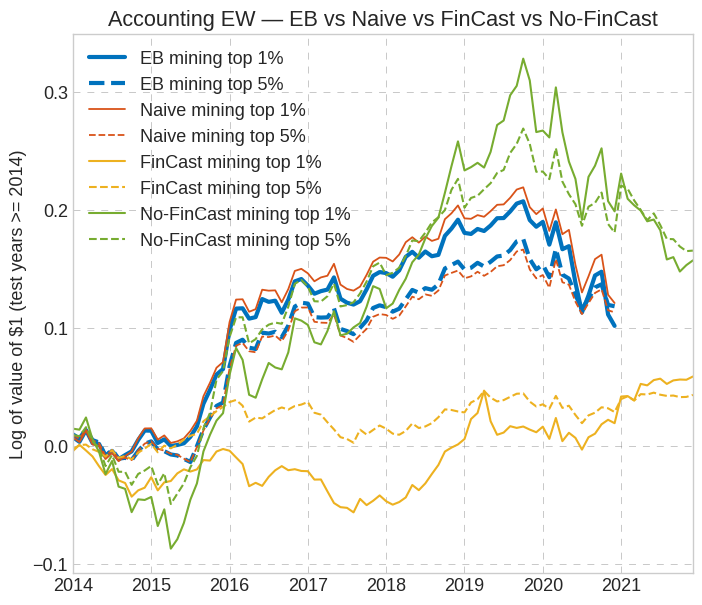


✅ Đã lưu biểu đồ: /content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/figs/beststrats-cret_acct_ew.pdf


In [ ]:
# -*- coding: utf-8 -*-
"""
So sánh EB Mining / Naive Mining / FinCast Mining / No-FinCast Mining
CHỈ cho family: acct_ew (DataMinedLongShortReturnsEW)
"""
import os, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import string
import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({"font.size": 13})
COLORS = ['#0072BD', '#D95319', '#EDB120', '#7E2F8E',
          '#77AC30', '#4DBEEE', '#A2142F']

# ============================================================
# 0. Config
# ============================================================
path_input = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/')
path_figs = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/figs/')
path_tables = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/tables/')
os.makedirs(path_figs, exist_ok=True)
os.makedirs(path_tables, exist_ok=True)

estimates_file = "hight_throughput_output/Nelly_Predict_SignalYear.csv.gzip"


FAMILY_RAW = 'DataMinedLongShortReturnsEW'   # tên gốc trong data (khớp với FinCast/No-FinCast pipeline)
FAMILY_SHORT = 'acct_ew'                      # tên rút gọn dùng trong estimates_file / EB pipeline
FAMILY_LABEL = 'Accounting EW'

ret_freq_adj = 12
oos_freq_adj = 1
YEAR_MIN = 1963
YEAR_MAX = 2020
TEST_YEAR_CUTOFF = 2014   # phải khớp với test_year_cutoff dùng lúc train cả 2 LSTM

FINCAST_PRED_PATH = (
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/'
    'results_per_family_onlyAcctEW/predictions_test_FinCast_DataMinedLongShortReturnsEW.parquet'
)
NOFINCAST_PRED_PATH = (
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/'
    'results_per_family_onlyAcctEW/predictions_test_V3_DataMinedLongShortReturnsEW.parquet'
)

SIGNAL_FAMILY_NAME_MAP = {
    "DataMinedLongShortReturnsEW": "acct_ew",
}

# ============================================================
# 1. Load monthly returns — CHỈ family acct_ew
# ============================================================
df = pd.read_csv(path_input / 'DataMinedStrategies' / f'{FAMILY_RAW}.csv')
df['day'] = 1
df['date'] = pd.to_datetime(df[['year', 'month', 'day']])
df['year'] = df['date'].dt.year
df = df[['signalid', 'date', 'year', 'ret']].sort_values(['signalid', 'date'])
df['signal_family'] = FAMILY_RAW
df_signal_ret = df.query('year>=@YEAR_MIN').copy()
df_signal_ret['signal_family'] = df_signal_ret['signal_family'].replace(SIGNAL_FAMILY_NAME_MAP)
df_signal_ret['signalid'] = df_signal_ret['signalid'].astype(str)

# ============================================================
# 2. Load estimates (IS tstat, EB pred_ret, thetahat, nobs) — lọc CHỈ acct_ew
# ============================================================
df_oos = df_signal_ret.rename(columns={'year': 'oos_begin_year'})

df_est = pd.read_csv(path_input / estimates_file)
df_est = df_est.rename(columns={'mean_ret': 'ret'}).drop(columns=['s_flag'])
df_est['signal_family'] = df_est['signal_family'].replace(SIGNAL_FAMILY_NAME_MAP)
df_est = df_est.query('signal_family == @FAMILY_SHORT').copy()
df_est['signalid'] = df_est['signalid'].astype(str)

cols = ['signal_family', 'signalid', 'date', 'oos_begin_year', 'ret']
df_est_oos = df_est.merge(df_oos[cols], how='inner', suffixes=('_is', '_oos'),
                           on=['signal_family', 'signalid', 'oos_begin_year'])
df_est_oos = df_est_oos.rename(columns={'tstat': 'tstat_is'})
print(f"df_est_oos (family={FAMILY_SHORT}): {len(df_est_oos)} dòng")

# ============================================================
# 3. Get best strategies based on predicted return (EB, Naive)
# ============================================================
cols = ['signal_family', 'signalid', 'date', 'pred_ret', 'ret_oos', 'thetahat',
        'tstat_is', 'nobs', 'oos_begin_year']
df_signed = df_est_oos.query('oos_begin_year<=@YEAR_MAX')[cols].copy()

####################
# Naive Mining — sign theo IS t-stat
####################
df_signed['sign_tstat'] = np.sign(df_signed['tstat_is'])
df_signed['tstat_is'] = df_signed['sign_tstat']*df_signed['tstat_is']
df_signed['ret_oos_tstat'] = df_signed['sign_tstat']*df_signed['ret_oos']
df_signed['rank_pct_tstat'] = df_signed.groupby('date')['tstat_is'].transform(
    lambda x: x.rank(pct=True)) * 100

####################
# EB Mining — sign theo EB prediction, rank theo Sharpe ratio dự đoán
####################
df_signed['sign'] = np.sign(df_signed['pred_ret'])
df_signed['pred_ret'] = df_signed['sign']*df_signed['pred_ret']
df_signed['ret_oos'] = df_signed['sign']*df_signed['ret_oos']
df_signed['thetahat'] = df_signed['sign']*df_signed['thetahat']
df_signed['SRahat'] = (df_signed['thetahat']/np.sqrt(df_signed['nobs'])) * np.sqrt(ret_freq_adj)
df_signed['rank_pct'] = df_signed.groupby('date')['SRahat'].transform(
    lambda x: x.rank(pct=True)) * 100

extreme_ranks = [1, 5, 10]
df_best_ret = []
for sort_var, sfx in [('SRahat', ''), ('tstat_is', '_tstat')]:
    for rank in extreme_ranks:
        d = df_signed.loc[df_signed[f'rank_pct{sfx}'] >= 100-rank,
                           ['date', f'ret_oos{sfx}']].copy()
        d['ret_oos'] = d[f'ret_oos{sfx}']
        d = d.groupby('date').agg(ret_oos=('ret_oos', 'mean'),
                                   nstrat=('ret_oos', 'count')).reset_index()
        d['pctmin'] = rank
        d['sort_var'] = sort_var
        df_best_ret.append(d)
df_best_ret = pd.concat(df_best_ret)

# ============================================================
# 4. FinCast Mining & No-FinCast Mining
# ============================================================
def build_lstm_best_ret(pred_path, pred_col, sort_var_name, df_est_oos, extreme_ranks, test_year_cutoff):
    df_pred = pd.read_parquet(pred_path)
    df_pred['signalid'] = df_pred['signalid'].astype(str)
    # đảm bảo signal_family khớp tên (FAMILY_RAW hay FAMILY_SHORT tuỳ file predictions dùng tên nào)
    fam_in_pred = df_pred['signal_family'].iloc[0]
    df_est_oos_use = df_est_oos.copy()
    if fam_in_pred != df_est_oos_use['signal_family'].iloc[0]:
        df_est_oos_use['signal_family'] = fam_in_pred  # đồng bộ tên để merge được

    df_est_oos_lstm = df_est_oos_use.merge(
        df_pred[['signal_family', 'signalid', 'oos_begin_year', pred_col]],
        how='inner', on=['signal_family', 'signalid', 'oos_begin_year']
    )
    df_est_oos_lstm = df_est_oos_lstm.query('oos_begin_year >= @test_year_cutoff').copy()
    print(f"  [{sort_var_name}] merged rows: {len(df_est_oos_lstm)}")

    df_est_oos_lstm['sign_lstm'] = np.sign(df_est_oos_lstm[pred_col])
    df_est_oos_lstm['ret_oos_lstm'] = df_est_oos_lstm['sign_lstm'] * df_est_oos_lstm['ret_oos']
    df_est_oos_lstm['rank_pct_lstm'] = df_est_oos_lstm.groupby('date')[pred_col].transform(
        lambda x: x.abs().rank(pct=True)) * 100

    out = []
    for rank in extreme_ranks:
        d = df_est_oos_lstm.loc[df_est_oos_lstm['rank_pct_lstm'] >= 100 - rank,
                                 ['date', 'ret_oos_lstm']].copy()
        d = d.rename(columns={'ret_oos_lstm': 'ret_oos'})
        d = d.groupby('date').agg(ret_oos=('ret_oos', 'mean'),
                                   nstrat=('ret_oos', 'count')).reset_index()
        d['pctmin'] = rank
        d['sort_var'] = sort_var_name
        out.append(d)
    return pd.concat(out)

print("Đang build FinCast Mining...")
df_best_ret_fincast = build_lstm_best_ret(
    FINCAST_PRED_PATH, 'pred_ret_fincast', 'pred_fincast',
    df_est_oos, extreme_ranks, TEST_YEAR_CUTOFF
)
print("Đang build No-FinCast Mining...")
df_best_ret_nofincast = build_lstm_best_ret(
    NOFINCAST_PRED_PATH, 'pred_ret_V3', 'pred_nofincast',
    df_est_oos, extreme_ranks, TEST_YEAR_CUTOFF
)

# lọc EB/Naive về cùng khoảng năm test để so sánh công bằng
df_best_ret_eb_naive_test = df_best_ret.merge(
    df_signed[['date', 'oos_begin_year']].drop_duplicates(), on='date', how='left'
).query('oos_begin_year >= @TEST_YEAR_CUTOFF').drop(columns=['oos_begin_year'])

df_best_ret_all = pd.concat([
    df_best_ret_eb_naive_test,
    df_best_ret_fincast,
    df_best_ret_nofincast,
])

# ============================================================
# 5. Bảng tổng hợp: mean return, t-stat, Sharpe ratio — CHỈ acct_ew, test >= 2014
# ============================================================
sorting_types = [
    ('SRahat', 'EB Mining'),
    ('tstat_is', 'Naive Mining'),
    ('pred_fincast', 'FinCast Mining'),
    ('pred_nofincast', 'No-FinCast Mining'),
]
best_sumr = df_best_ret_all.copy()
for typ, lab in sorting_types:
    mask = best_sumr['sort_var'] == typ
    best_sumr.loc[mask, 'pctmin'] = best_sumr.loc[mask, 'pctmin'].replace(
        {1: f'{lab} Top 1\%', 5: f'{lab} Top 5\%', 10: f'{lab} Top 10\%'})
best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos': 'ret'})
best_sumr['year'] = best_sumr['date'].dt.year

row_order = {
    'SRahat': ['EB Mining Top 1\%', 'EB Mining Top 5\%', 'EB Mining Top 10\%'],
    'tstat_is': ['Naive Mining Top 1\%', 'Naive Mining Top 5\%', 'Naive Mining Top 10\%'],
    'pred_fincast': ['FinCast Mining Top 1\%', 'FinCast Mining Top 5\%', 'FinCast Mining Top 10\%'],
    'pred_nofincast': ['No-FinCast Mining Top 1\%', 'No-FinCast Mining Top 5\%', 'No-FinCast Mining Top 10\%'],
}
sort_var_ls = ['SRahat', 'tstat_is', 'pred_fincast', 'pred_nofincast']
alphabets = string.ascii_uppercase

tabdat = []
for i, sort_var in enumerate(sort_var_ls):
    d = best_sumr.query("sort_var==@sort_var")
    d = d.groupby(["name"]).agg({
        'ret': ['mean', 'std', 'count'],
        'nstrat': 'mean'}
    )
    d.columns = [f'{c0}_{c1}' for c0, c1 in d.columns]
    d['sr'] = d.eval('ret_mean/ret_std')
    d['tstat'] = d.eval('ret_mean/ret_std*sqrt(ret_count)')
    d = d.drop(columns=['ret_std', 'ret_count'])
    d = d[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
    d = d.loc[row_order[sort_var]]
    line = pd.DataFrame(index=[f'Panel {alphabets[i]}'], columns=d.columns)
    d = pd.concat([line, d])
    d.loc[''] = np.nan
    tabdat.append(d)
tabdat = pd.concat(tabdat).iloc[:-1]

tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

cols = ['ret_mean', 'tstat', 'sr']
tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}' if pd.notnull(x) else '')
tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}' if pd.notnull(x) else '')
tabdat = tabdat.replace({'nan': ''})

print(f"\n=== Bảng so sánh — family: {FAMILY_LABEL}, test years >= {TEST_YEAR_CUTOFF} ===")
print(tabdat)

tabdat_export = tabdat.rename(
    columns={'nstrat_mean': '\\makecell{Num Strats \\\\ Combined}',
             'ret_mean': '\\makecell{Mean Return \\\\ (\\% ann)}',
             'tstat': '$t$-stat', 'sr': '\\makecell{Sharpe Ratio \\\\ (ann)}'})
col_format = 'l' + 'c' * tabdat_export.shape[1]
latex_table = tabdat_export.style.to_latex(column_format=col_format, hrules=True)

part = r'\\\\\n &  &  &  &'
repl = r'\\\\\n\\hline\n &  &  &  &'
latex_tableF = re.sub(part, repl, latex_table)
part = r'(\nPanel [A-Z] &  &  &  &  \\\\\n)'
repl = r'\1\\hline\n'
latex_tableF = re.sub(part, repl, latex_tableF)

with open(path_tables / f'beststrats_{FAMILY_SHORT}.tex', 'w') as fh:
    fh.write(latex_tableF)
print(f"\n✅ Đã lưu bảng LaTeX: {path_tables / f'beststrats_{FAMILY_SHORT}.tex'}")

# ============================================================
# 6. Biểu đồ cumulative return — Top 1%, Top 5% mỗi phương pháp
# ============================================================
extreme_ranks_plot = [1, 5]
df_plot = df_best_ret_all.query('pctmin in @extreme_ranks_plot').copy()

label_map = {
    'SRahat': {1: 'EB mining top 1%', 5: 'EB mining top 5%'},
    'tstat_is': {1: 'Naive mining top 1%', 5: 'Naive mining top 5%'},
    'pred_fincast': {1: 'FinCast mining top 1%', 5: 'FinCast mining top 5%'},
    'pred_nofincast': {1: 'No-FinCast mining top 1%', 5: 'No-FinCast mining top 5%'},
}
for typ, mapping in label_map.items():
    mask = df_plot['sort_var'] == typ
    df_plot.loc[mask, 'pctmin'] = df_plot.loc[mask, 'pctmin'].replace(mapping)

df_plot = df_plot.pivot(columns=['sort_var', 'pctmin'], index='date', values='ret_oos').sort_index()
df_plot = (1 + df_plot / 100).cumprod()

color_dic = {
    'SRahat': (COLORS[0], 3),
    'tstat_is': (COLORS[1], 1.3),
    'pred_fincast': (COLORS[2], 1.5),
    'pred_nofincast': (COLORS[4], 1.5),
}

fig, ax = plt.subplots(figsize=(8, 7))
for typ, params in color_dic.items():
    clr, lwidth = params
    if typ not in df_plot.columns.get_level_values(0):
        continue
    temp = np.log(df_plot[typ])
    temp.plot(ax=ax, color=[clr, clr], style=['-', '--'], linewidth=lwidth)

plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)
ax.set_ylabel(f'Log of value of $1 (test years >= {TEST_YEAR_CUTOFF})')
ax.set_xlabel('')
ax.set_title(f'{FAMILY_LABEL} — EB vs Naive vs FinCast vs No-FinCast')
plt.legend(loc='upper left', alignment='left')
fig.savefig(path_figs / f'beststrats-cret_{FAMILY_SHORT}.pdf', format='pdf', bbox_inches="tight")
plt.show()

print(f"\n✅ Đã lưu biểu đồ: {path_figs / f'beststrats-cret_{FAMILY_SHORT}.pdf'}")

# training fincast lstm att cho past return ew

In [ ]:
#fincast+lstm+att
import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr
from huggingface_hub import hf_hub_download
# 0. Config — CHỈ 1 FAMILY
FAMILY = 'PastReturnSignalsLongShort_ew'
KEYS_DIR = '/content/fincast_embeddings'
REPO_ID = "ngandh/fincast-embeddings"
REPO_TYPE = "dataset"

rollsignal_path = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
ROLLSIGNAL_USECOLS = ['signalid', 'signal_family', 's_flag', 'oos_begin_year', 'tstat', 'mean_ret']
RESULTS_DIR = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_onlyAcctVW'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Mốc năm cố định — PHẢI KHỚP với bản train_lstm_no_fincast (raw LSTM) để so sánh công bằng
VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014
# 1. Tải hidden (.npy) + keys (.parquet) cho ĐÚNG 1 family
hidden_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=f"fincast_hidden_{FAMILY}.npy",
    repo_type=REPO_TYPE,
    token=hf_token,
)
keys_path = '/content/fincast_keys_PastReturnSignalsLongShort_ew.parquet'
assert os.path.exists(keys_path), f"Không tìm thấy {keys_path}"

print(f"hidden_path: {hidden_path}")
print(f"keys_path:   {keys_path}")

hidden_arr = np.load(hidden_path, mmap_mode='r')   # KHÔNG load hết vào RAM
print("hidden_arr shape:", hidden_arr.shape)

fincast_hidden_PastReturnSignalsLongShor(…): reconstructing file:   0%|          |  0.00B / 15.5GB            

fincast_hidden_PastReturnSignalsLongShor(…): downloading bytes:           |  0.00B            

hidden_path: /root/.cache/huggingface/hub/datasets--ngandh--fincast-embeddings/snapshots/2214269a23d64b63c1db6536540f1f20bd13af89/fincast_hidden_PastReturnSignalsLongShort_ew.npy
keys_path:   /content/fincast_keys_PastReturnSignalsLongShort_ew.parquet
hidden_arr shape: (756678, 4, 1280)


In [ ]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr
from huggingface_hub import hf_hub_download   # <-- cần thêm lại nếu chưa import (để tải hidden_arr mới)

#  Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ĐỔI FAMILY VÀ CÁC PATH LIÊN QUAN — DUY NHẤT PHẦN CẦN SỬA
FAMILY = 'PastReturnSignalsLongShort_ew'          # <-- ĐỔI từ 'DataMinedLongShortReturnsEW'
REPO_ID = "ngandh/fincast-embeddings"
REPO_TYPE = "dataset"

rollsignal_path = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
ROLLSIGNAL_USECOLS = ['signalid', 'signal_family', 's_flag', 'oos_begin_year', 'tstat', 'mean_ret']

RESULTS_DIR = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_pastret_ew'  # <-- ĐỔI thư mục kết quả, tránh ghi đè family cũ
os.makedirs(RESULTS_DIR, exist_ok=True)

VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014
#Tải hidden (.npy) + keys (.parquet) — CHO FAMILY MỚI
hidden_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=f"fincast_hidden_{FAMILY}.npy",       # <-- tự động đổi theo FAMILY
    repo_type=REPO_TYPE,
    token=hf_token,
)
keys_path = f'/content/fincast_keys_{FAMILY}.parquet'   # <-- ĐỔI tên file cho khớp family mới
assert os.path.exists(keys_path), f"Không tìm thấy {keys_path} — cần tải/copy file keys cho family {FAMILY} trước"

print(f"hidden_path: {hidden_path}")
print(f"keys_path:   {keys_path}")

hidden_arr = np.load(hidden_path, mmap_mode='r')
print("hidden_arr shape:", hidden_arr.shape)

#Merge rollsignal (IS/OOS) với keys — CHỈ 1 FAMILY (không đổi logic)
def join_rollsignal_with_sequence(rollsignal_path, keys_path):
    rollsignal = pd.read_csv(rollsignal_path, usecols=ROLLSIGNAL_USECOLS)
    rollsignal['signalid'] = rollsignal['signalid'].astype(str)
    rollsignal['tstat'] = rollsignal['tstat'].astype(np.float32)
    rollsignal['mean_ret'] = rollsignal['mean_ret'].astype(np.float32)

    is_df = rollsignal[rollsignal['s_flag'] == 'IS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'tstat', 'mean_ret']
    ].rename(columns={'tstat': 'tstat_IS', 'mean_ret': 'mean_ret_IS'})

    oos_df = rollsignal[rollsignal['s_flag'] == 'OOS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'mean_ret']
    ].rename(columns={'mean_ret': 'mean_ret_OOS'})

    del rollsignal
    gc.collect()

    keys_df = pd.read_parquet(keys_path)
    keys_df['signalid'] = keys_df['signalid'].astype(str)
    if 'emb_idx' not in keys_df.columns:
        keys_df['emb_idx'] = np.arange(len(keys_df), dtype=np.int32)

    dup_keys = keys_df.duplicated(subset=['signalid', 'signal_family', 'oos_begin_year']).sum()
    assert dup_keys == 0, f"keys_df có {dup_keys} dòng key bị trùng lặp — kiểm tra lại file extraction"
    assert keys_df['emb_idx'].is_unique, "emb_idx trong keys_df không unique"

    fam = keys_df['signal_family'].iloc[0] if len(keys_df) > 0 else None
    is_df_fam = is_df[is_df['signal_family'] == fam] if fam else is_df
    print(f"[Chẩn đoán] Family trong keys_df: {sorted(keys_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Family trong is_df (rollsignal, IS): {sorted(is_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): {len(is_df_fam)}")
    print(f"[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    {len(keys_df)}")
    print(f"[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: "
          f"{len(keys_df) / max(len(is_df_fam), 1) * 100:.1f}%")

    is_df = is_df.merge(
        keys_df[['signalid', 'signal_family', 'oos_begin_year', 'emb_idx']],
        on=['signalid', 'signal_family', 'oos_begin_year'], how='left'
    )
    n_matched = is_df['emb_idx'].notna().sum()
    print(f"Matched: {n_matched}/{len(is_df)} ({n_matched/len(is_df)*100:.1f}%)")

    del keys_df
    gc.collect()
    return is_df, oos_df

is_df, oos_df = join_rollsignal_with_sequence(rollsignal_path, keys_path)
merged = is_df.merge(oos_df, on=['signalid', 'signal_family', 'oos_begin_year'], how='inner')
del is_df, oos_df
gc.collect()

merged = merged.dropna(subset=['emb_idx', 'tstat_IS', 'mean_ret_IS', 'mean_ret_OOS'])
merged['emb_idx'] = merged['emb_idx'].astype(np.int32)

dup_merged = merged['emb_idx'].duplicated().sum()
assert dup_merged == 0, f"merged có {dup_merged} dòng emb_idx bị trùng lặp — kiểm tra lại merge key"

print("Số signal-window:", len(merged))
print(merged['signal_family'].value_counts())

# ⚠️ Kiểm tra ngay: merged chỉ nên có đúng 1 family = PastReturnSignalsLongShort_ew
assert merged['signal_family'].nunique() == 1, "merged chứa nhiều hơn 1 family — kiểm tra lại keys_path"
assert merged['signal_family'].iloc[0] == FAMILY, \
    f"merged['signal_family'] = {merged['signal_family'].iloc[0]}, không khớp FAMILY = {FAMILY}"

# Model, metrics, batch iterator (streaming) — KHÔNG ĐỔI
class LSTMAttentionRegressor(nn.Module):
    def __init__(self, seq_input_dim=1280, extra_feat_dim=2, lstm_hidden=128, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=seq_input_dim, hidden_size=lstm_hidden, num_layers=1,
            batch_first=True, bidirectional=True,
        )
        lstm_out_dim = lstm_hidden * 2
        self.attn_proj = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_v = nn.Linear(lstm_out_dim, 1, bias=False)
        head_in = lstm_out_dim + extra_feat_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, seq, extra_feats):
        lstm_out, _ = self.lstm(seq)
        scores = self.attn_v(torch.tanh(self.attn_proj(lstm_out))).squeeze(-1)
        attn_weights = torch.softmax(scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1)
        combined = torch.cat([context, extra_feats], dim=1)
        pred = self.head(combined).squeeze(-1)
        return pred, attn_weights


def compute_scaler_stats_streaming(hidden_arr, idx_array, batch_size=50000):
    D = hidden_arr.shape[2]
    sum_ = np.zeros(D, dtype=np.float64)
    sum_sq = np.zeros(D, dtype=np.float64)
    count = 0
    n = len(idx_array)
    idx_sorted = np.sort(idx_array)
    for i in range(0, n, batch_size):
        batch_idx = idx_sorted[i:i+batch_size]
        chunk = np.asarray(hidden_arr[batch_idx]).reshape(-1, D)
        sum_ += chunk.sum(axis=0)
        sum_sq += (chunk.astype(np.float64) ** 2).sum(axis=0)
        count += chunk.shape[0]
    mean = sum_ / count
    std = np.sqrt(sum_sq / count - mean ** 2)
    return mean.astype(np.float32), std.astype(np.float32)


def iterate_batches_streaming(idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                               batch_size, shuffle=True, device='cuda'):
    n = len(idx_array)
    order = np.random.permutation(n) if shuffle else np.arange(n)
    for start in range(0, n, batch_size):
        batch_order = order[start:start + batch_size]
        emb_ids = idx_array[batch_order]
        sort_order = np.argsort(emb_ids)
        emb_ids_sorted = emb_ids[sort_order]
        seq_b = np.asarray(hidden_arr[emb_ids_sorted])
        seq_b = (seq_b - mean_) / (std_ + 1e-8)
        seq_b = torch.from_numpy(seq_b.astype(np.float32))
        feat_b = torch.from_numpy(feat_arr[batch_order][sort_order].astype(np.float32))
        yb = torch.from_numpy(y_arr[batch_order][sort_order].astype(np.float32))
        if device != 'cpu':
            seq_b = seq_b.to(device, non_blocking=True)
            feat_b = feat_b.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
        yield seq_b, feat_b, yb


def eval_streaming_ordered(model, idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                            batch_size, device):
    model.eval()
    all_pred, all_true, all_idx = [], [], []
    n = len(idx_array)
    order = np.arange(n)
    with torch.no_grad():
        for start in range(0, n, batch_size):
            batch_order = order[start:start + batch_size]
            emb_ids = idx_array[batch_order]
            sort_order = np.argsort(emb_ids)
            emb_ids_sorted = emb_ids[sort_order]
            seq_b = np.asarray(hidden_arr[emb_ids_sorted])
            seq_b = (seq_b - mean_) / (std_ + 1e-8)
            seq_b = torch.from_numpy(seq_b.astype(np.float32)).to(device)
            feat_b = torch.from_numpy(
                feat_arr[batch_order][sort_order].astype(np.float32)
            ).to(device)
            y_b = y_arr[batch_order][sort_order]
            pred_b, _ = model(seq_b, feat_b)
            all_pred.append(pred_b.cpu().numpy())
            all_true.append(y_b)
            all_idx.append(emb_ids_sorted)
    pred_final = np.concatenate(all_pred)
    y_final = np.concatenate(all_true)
    idx_final = np.concatenate(all_idx)
    return pred_final, y_final, idx_final


def compute_regression_metrics(y_true, y_pred, prefix=''):
    y_true_sign = (y_true > 0).astype(int)
    y_pred_sign = (y_pred > 0).astype(int)
    return {
        f'{prefix}mse': float(np.mean((y_pred - y_true) ** 2)),
        f'{prefix}mae': float(mean_absolute_error(y_true, y_pred)),
        f'{prefix}r2': float(r2_score(y_true, y_pred)),
        f'{prefix}dir_acc': float(accuracy_score(y_true_sign, y_pred_sign)),
        f'{prefix}precision': float(precision_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}recall': float(recall_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}f1': float(f1_score(y_true_sign, y_pred_sign, zero_division=0)),
    }


def portfolio_relevant_report_yearly(y_true, y_pred, oos_years, n_deciles=10):
    df = pd.DataFrame({'year': oos_years, 'y_true': y_true, 'y_pred': y_pred})
    ic_rows = []
    for yr, g in df.groupby('year'):
        if len(g) < 5:
            continue
        ic_yr, _ = spearmanr(g['y_pred'], g['y_true'])
        ic_rows.append({'oos_begin_year': yr, 'n': len(g), 'IC': ic_yr})
    ic_by_year_df = pd.DataFrame(ic_rows).sort_values('oos_begin_year')
    ic_mean = ic_by_year_df['IC'].mean()
    ic_std = ic_by_year_df['IC'].std()
    print(f"\nMean yearly IC: {ic_mean:.4f} (std={ic_std:.4f}, n_years={len(ic_by_year_df)})")
    print(ic_by_year_df.to_string(index=False))

    decile_rows = []
    for yr, g in df.groupby('year'):
        g = g.copy()
        try:
            g['decile'] = pd.qcut(g['y_pred'], n_deciles, labels=np.arange(1, n_deciles + 1))
        except ValueError:
            continue
        for d, sub in g.groupby('decile', observed=True):
            decile_rows.append({
                'year': yr, 'decile': int(d), 'n': len(sub),
                'mean_pred': sub['y_pred'].mean(),
                'mean_actual_ret': sub['y_true'].mean(),
            })
    decile_by_year_df = pd.DataFrame(decile_rows)

    decile_agg = decile_by_year_df.groupby('decile').agg(
        n=('n', 'sum'),
        mean_pred=('mean_pred', 'mean'),
        mean_actual_ret=('mean_actual_ret', 'mean'),
    ).reset_index()
    print("\nDecile spread (trung bình các năm, KHÔNG pooled):")
    print(decile_agg.to_string(index=False))

    is_monotonic = decile_agg['mean_actual_ret'].is_monotonic_increasing

    ls_by_year = decile_by_year_df.pivot(index='year', columns='decile', values='mean_actual_ret')
    ls_spread_by_year = ls_by_year[n_deciles] - ls_by_year[1]
    ls_spread_mean = ls_spread_by_year.mean()
    ls_spread_tstat = ls_spread_mean / ls_spread_by_year.std() * np.sqrt(len(ls_spread_by_year))
    print(f"\nLong-short spread (trung bình theo năm): {ls_spread_mean:.4f}, "
          f"t-stat: {ls_spread_tstat:.4f}")

    return {
        'ic_by_year': ic_by_year_df, 'ic_mean': float(ic_mean), 'ic_std': float(ic_std),
        'decile_by_year': decile_by_year_df, 'decile_agg': decile_agg,
        'is_monotonic': bool(is_monotonic),
        'long_short_spread_by_year': ls_spread_by_year,
        'long_short_spread_mean': float(ls_spread_mean),
        'long_short_spread_tstat': float(ls_spread_tstat),
    }


# Train + eval streaming
def train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100, lr=1e-3, seed=42,
    val_year_cutoff=VAL_YEAR_CUTOFF, test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path='training_log.csv',
    eval_every=5, batch_size=1024, device=None,
    early_stopping_patience=15,
    checkpoint_dir=None, checkpoint_every=5,
    scaler_batch_size=50000,
):
    set_seed(seed)
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Device: {device}, batch_size={batch_size}")

    emb_idx_all = merged['emb_idx'].to_numpy(dtype=np.int64)
    extra_feats_all = merged[['tstat_IS', 'mean_ret_IS']].to_numpy(dtype=np.float32)
    y_ret = merged['mean_ret_OOS'].to_numpy(dtype=np.float32)
    years_all = merged['oos_begin_year'].to_numpy()

    train_mask = years_all < val_year_cutoff
    val_mask   = (years_all >= val_year_cutoff) & (years_all < test_year_cutoff)
    test_mask  = years_all >= test_year_cutoff

    assert train_mask.sum() > 0, "Train set rỗng, kiểm tra lại val_year_cutoff"
    assert val_mask.sum()   > 0, "Validation set rỗng, kiểm tra lại val_year_cutoff/test_year_cutoff"
    assert test_mask.sum()  > 0, "Test set rỗng, kiểm tra lại test_year_cutoff"

    print(f"Split theo năm CỐ ĐỊNH: train < {val_year_cutoff} (n={train_mask.sum()}), "
          f"val [{val_year_cutoff}, {test_year_cutoff}) (n={val_mask.sum()}), "
          f"test >= {test_year_cutoff} (n={test_mask.sum()})")

    idx_train, idx_val, idx_test = emb_idx_all[train_mask], emb_idx_all[val_mask], emb_idx_all[test_mask]
    feat_train, feat_val, feat_test = extra_feats_all[train_mask], extra_feats_all[val_mask], extra_feats_all[test_mask]
    y_train, y_val, y_test = y_ret[train_mask], y_ret[val_mask], y_ret[test_mask]
    years_train, years_val, years_test = years_all[train_mask], years_all[val_mask], years_all[test_mask]

    del emb_idx_all, extra_feats_all, y_ret, years_all
    gc.collect()

    print("Đang tính mean/std của embedding (streaming, CHỈ trên train)...")
    mean_, std_ = compute_scaler_stats_streaming(hidden_arr, idx_train, batch_size=scaler_batch_size)

    feat_scaler = StandardScaler(copy=False)
    feat_train = feat_scaler.fit_transform(feat_train).astype(np.float32)
    feat_val   = feat_scaler.transform(feat_val).astype(np.float32)
    feat_test  = feat_scaler.transform(feat_test).astype(np.float32)

    D = hidden_arr.shape[2]
    model = LSTMAttentionRegressor(seq_input_dim=D, extra_feat_dim=feat_train.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    if checkpoint_dir is not None:
        os.makedirs(checkpoint_dir, exist_ok=True)
    best_ckpt_path = f'{checkpoint_dir}/best.pt' if checkpoint_dir else None
    last_ckpt_path = f'{checkpoint_dir}/last.pt' if checkpoint_dir else None

    history = []
    best_val_ic = -float('inf')
    best_state = None
    epochs_no_improve = 0

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss_sum, n_seen = 0.0, 0
        for seq_b, feat_b, yb in iterate_batches_streaming(
            idx_train, feat_train, y_train, hidden_arr, mean_, std_,
            batch_size=batch_size, shuffle=True, device=device,
        ):
            optimizer.zero_grad()
            pred, _ = model(seq_b, feat_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        train_mse_running = train_loss_sum / max(n_seen, 1)

        do_eval = (epoch + 1) % eval_every == 0 or epoch == epochs - 1
        if do_eval:
            model.eval()
            val_preds, val_trues = [], []
            with torch.no_grad():
                for seq_b, feat_b, yb in iterate_batches_streaming(
                    idx_val, feat_val, y_val, hidden_arr, mean_, std_,
                    batch_size=batch_size, shuffle=False, device=device,
                ):
                    pred, _ = model(seq_b, feat_b)
                    val_preds.append(pred.cpu().numpy())
                    val_trues.append(yb.cpu().numpy())
            val_pred_arr = np.concatenate(val_preds)
            val_true_arr = np.concatenate(val_trues)
            val_metrics = compute_regression_metrics(val_true_arr, val_pred_arr, prefix='val_')
            val_ic, _ = spearmanr(val_pred_arr, val_true_arr)
            val_ic = float(val_ic) if not np.isnan(val_ic) else -1.0
            val_metrics['val_ic'] = val_ic

            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE: {train_mse_running:.6f} | "
                  f"Val MSE: {val_metrics['val_mse']:.6f} | Val IC: {val_ic:.4f}")
            history.append({'epoch': epoch+1, 'train_mse_running': train_mse_running, **val_metrics})

            if val_ic > best_val_ic + 1e-8:
                best_val_ic = val_ic
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_no_improve = 0
                if best_ckpt_path:
                    torch.save({'epoch': epoch+1, 'model_state': best_state, 'val_ic': best_val_ic}, best_ckpt_path)
            else:
                epochs_no_improve += eval_every
                if epochs_no_improve >= early_stopping_patience:
                    print(f"⏹ Early stopping tại epoch {epoch+1}")
                    break
        else:
            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE (running): {train_mse_running:.6f}")

        if last_ckpt_path and ((epoch+1) % checkpoint_every == 0 or epoch == epochs-1):
            torch.save({'epoch': epoch+1, 'model_state': model.state_dict(),
                        'optimizer_state': optimizer.state_dict(), 'history': history}, last_ckpt_path)

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"✅ Khôi phục best model (val_IC={best_val_ic:.4f})")

    history_df = pd.DataFrame(history)
    history_df.to_csv(log_path, index=False)

    pred_nn, y_test_ordered, idx_test_ordered = eval_streaming_ordered(
        model, idx_test, feat_test, y_test, hidden_arr, mean_, std_,
        batch_size=batch_size, device=device,
    )

    idx_to_year = dict(zip(idx_test, years_test))
    years_test_ordered = np.array([idx_to_year[i] for i in idx_test_ordered])

    portfolio_report = portfolio_relevant_report_yearly(y_test_ordered, pred_nn, oos_years=years_test_ordered)

    results = {
        'pred_nn': pred_nn,
        'y_test': y_test_ordered,
        'years_test': years_test_ordered,
        'idx_test': idx_test_ordered,
        'best_val_ic': best_val_ic,
        'val_year_cutoff': val_year_cutoff,
        'test_year_cutoff': test_year_cutoff,
    }
    return model, mean_, std_, feat_scaler, results, history_df, portfolio_report


# Chạy train — FAMILY = PastReturnSignalsLongShort_ew
fam_log_path = f'{RESULTS_DIR}/log_{FAMILY}.csv'
fam_ckpt_dir = f'/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/checkpoints_{FAMILY}'  # <-- tự đổi theo FAMILY

model, mean_, std_, feat_scaler, results, history_df, portfolio_report = train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100,
    batch_size=1024,
    val_year_cutoff=VAL_YEAR_CUTOFF,
    test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path=fam_log_path,
    checkpoint_dir=fam_ckpt_dir,
    early_stopping_patience=15,
)

print(f"\n✅ Best validation IC (dùng để chọn checkpoint): {results['best_val_ic']:.4f}")
print(f"✅ Mean yearly test IC (đánh giá cuối cùng, không leak, không pooled): "
      f"{portfolio_report['ic_mean']:.4f}")

# Lưu predictions test kèm meta
idx_test_ordered = results['idx_test']

test_meta = merged[merged['emb_idx'].isin(idx_test_ordered)][
    ['signal_family', 'signalid', 'oos_begin_year', 'emb_idx']
].copy()
assert test_meta['emb_idx'].is_unique, "emb_idx trong test_meta bị trùng — merge sai key"
test_meta['signalid'] = test_meta['signalid'].astype(str)

idx_to_pos = {v: i for i, v in enumerate(idx_test_ordered)}
test_meta['_pos'] = test_meta['emb_idx'].map(idx_to_pos)
test_meta = test_meta.sort_values('_pos').drop(columns=['_pos', 'emb_idx']).reset_index(drop=True)

assert len(test_meta) == len(results['pred_nn']), \
    f"Số dòng lệch: test_meta={len(test_meta)} vs pred_nn={len(results['pred_nn'])}"

test_meta['pred_ret_fincast'] = results['pred_nn']

pred_out_path = f'{RESULTS_DIR}/predictions_test_FinCast_{FAMILY}.parquet'   # <-- tự đổi theo FAMILY
test_meta.to_parquet(pred_out_path, index=False)
print(f"✅ Đã lưu predictions FinCast: {pred_out_path}")
print(f"✅ Đã lưu checkpoint: {fam_ckpt_dir}/best.pt")

saved_check = pd.read_parquet(pred_out_path)
print(f"\nKiểm tra: tồn tại={os.path.exists(pred_out_path)}, shape={saved_check.shape}")

hidden_path: /root/.cache/huggingface/hub/datasets--ngandh--fincast-embeddings/snapshots/2214269a23d64b63c1db6536540f1f20bd13af89/fincast_hidden_PastReturnSignalsLongShort_ew.npy
keys_path:   /content/fincast_keys_PastReturnSignalsLongShort_ew.parquet
hidden_arr shape: (756678, 4, 1280)
[Chẩn đoán] Family trong keys_df: ['PastReturnSignalsLongShort_ew']
[Chẩn đoán] Family trong is_df (rollsignal, IS): ['DataMinedLongShortReturnsEW', 'DataMinedLongShortReturnsVW', 'PastReturnSignalsLongShort_ew', 'PastReturnSignalsLongShort_vw', 'TickerSignalsLongShort_ew', 'TickerSignalsLongShort_vw']
[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): 776080
[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    756678
[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: 97.5%
Matched: 756678/5113700 (14.8%)
Số signal-window: 756678
signal_family
PastReturnSignalsLongShort_ew    756678
Name: count, dtype: int64
Device: cuda, batch_size=1024
Split theo năm CỐ ĐỊNH: train < 2011 (n=543256), v

In [ ]:
import torch
import torch.nn as nn
import random
import time
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

# ============================================================
# 0. Reproducibility — đồng bộ với bản FinCast
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ============================================================
# ĐỔI FAMILY VÀ CÁC PATH LIÊN QUAN
# ============================================================
FAMILY = 'PastReturnSignalsLongShort_ew'   # <-- ĐỔI từ 'DataMinedLongShortReturnsEW'
RESULTS_DIR_EW = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_pastret_ew'  # <-- ĐỔI, khớp với thư mục dùng cho bản FinCast family này
v3_ckpt_dir = f'/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/checkpoints_{FAMILY}_V3'
os.makedirs(RESULTS_DIR_EW, exist_ok=True)
os.makedirs(v3_ckpt_dir, exist_ok=True)

VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014

# ============================================================
# Model — KHÔNG ĐỔI
# ============================================================
class LSTMAttentionRaw(nn.Module):
    def __init__(self, lookback=20, hidden_size=32, extra_feat_dim=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=1,
                             batch_first=True, bidirectional=True)
        lstm_out_dim = hidden_size * 2
        self.attn_proj = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_v = nn.Linear(lstm_out_dim, 1, bias=False)
        head_in = lstm_out_dim + extra_feat_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, seq, extra_feats):
        lstm_out, _ = self.lstm(seq)
        scores = self.attn_v(torch.tanh(self.attn_proj(lstm_out))).squeeze(-1)
        attn_weights = torch.softmax(scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1)
        combined = torch.cat([context, extra_feats], dim=1)
        return self.head(combined).squeeze(-1), attn_weights


def prepare_lookback_data(ret_panel, merged_fam, lookback=20):
    ret_panel = ret_panel.copy()
    ret_panel['year_month'] = ret_panel['date'].dt.to_period('M')
    ret_grouped = ret_panel.groupby(['signal_family', 'signalid'])
    seq_list, feat_list, y_list, meta_list = [], [], [], []
    for _, row in merged_fam.iterrows():
        fam, sid, yr = row['signal_family'], row['signalid'], row['oos_begin_year']
        is_end_period = pd.Period(year=int(yr) - 1, month=12, freq='M')
        is_start_period = is_end_period - (lookback - 1)
        try:
            sub = ret_grouped.get_group((fam, sid))
        except KeyError:
            continue
        sub = sub[(sub['year_month'] >= is_start_period) & (sub['year_month'] <= is_end_period)].sort_values('date')
        if len(sub) < lookback:
            continue
        seq_list.append(sub['ret'].values[-lookback:])
        feat_list.append([row['tstat_IS'], row['mean_ret_IS']])
        y_list.append(row['mean_ret_OOS'])
        meta_list.append((fam, sid, yr))
    seq_arr = np.array(seq_list, dtype=np.float32)
    feat_arr = np.array(feat_list, dtype=np.float32)
    y_arr = np.array(y_list, dtype=np.float32)
    meta_df = pd.DataFrame(meta_list, columns=['signal_family', 'signalid', 'oos_begin_year'])

    dup = meta_df.duplicated(subset=['signal_family', 'signalid', 'oos_begin_year']).sum()
    assert dup == 0, f"meta_df có {dup} dòng bị trùng lặp key — kiểm tra lại merged_fam đầu vào"
    return seq_arr, feat_arr, y_arr, meta_df


def portfolio_relevant_report_yearly(y_true, y_pred, oos_years, n_deciles=10):
    df = pd.DataFrame({'year': oos_years, 'y_true': y_true, 'y_pred': y_pred})
    ic_rows = []
    for yr, g in df.groupby('year'):
        if len(g) < 5:
            continue
        ic_yr, _ = spearmanr(g['y_pred'], g['y_true'])
        ic_rows.append({'oos_begin_year': yr, 'n': len(g), 'IC': ic_yr})
    ic_by_year_df = pd.DataFrame(ic_rows).sort_values('oos_begin_year')
    ic_mean = ic_by_year_df['IC'].mean()
    ic_std = ic_by_year_df['IC'].std()
    print(f"\nMean yearly IC: {ic_mean:.4f} (std={ic_std:.4f}, n_years={len(ic_by_year_df)})")
    print(ic_by_year_df.to_string(index=False))

    decile_rows = []
    for yr, g in df.groupby('year'):
        g = g.copy()
        try:
            g['decile'] = pd.qcut(g['y_pred'], n_deciles, labels=np.arange(1, n_deciles + 1))
        except ValueError:
            continue
        for d, sub in g.groupby('decile', observed=True):
            decile_rows.append({
                'year': yr, 'decile': int(d), 'n': len(sub),
                'mean_pred': sub['y_pred'].mean(),
                'mean_actual_ret': sub['y_true'].mean(),
            })
    decile_by_year_df = pd.DataFrame(decile_rows)

    decile_agg = decile_by_year_df.groupby('decile').agg(
        n=('n', 'sum'),
        mean_pred=('mean_pred', 'mean'),
        mean_actual_ret=('mean_actual_ret', 'mean'),
    ).reset_index()
    print("\nDecile spread (trung bình các năm, KHÔNG pooled):")
    print(decile_agg.to_string(index=False))

    is_monotonic = decile_agg['mean_actual_ret'].is_monotonic_increasing
    ls_by_year = decile_by_year_df.pivot(index='year', columns='decile', values='mean_actual_ret')
    ls_spread_by_year = ls_by_year[n_deciles] - ls_by_year[1]
    ls_spread_mean = ls_spread_by_year.mean()
    ls_spread_tstat = ls_spread_mean / ls_spread_by_year.std() * np.sqrt(len(ls_spread_by_year))
    print(f"\nLong-short spread (trung bình theo năm): {ls_spread_mean:.4f}, "
          f"t-stat: {ls_spread_tstat:.4f}")

    return {
        'ic_by_year': ic_by_year_df, 'ic_mean': float(ic_mean), 'ic_std': float(ic_std),
        'decile_by_year': decile_by_year_df, 'decile_agg': decile_agg,
        'is_monotonic': bool(is_monotonic),
        'long_short_spread_by_year': ls_spread_by_year,
        'long_short_spread_mean': float(ls_spread_mean),
        'long_short_spread_tstat': float(ls_spread_tstat),
    }


def train_lstm_no_fincast(seq_arr, feat_arr, y_arr, years_arr, lookback=20, hidden_size=32,
                           epochs=100, lr=1e-3, seed=42,
                           val_year_cutoff=VAL_YEAR_CUTOFF, test_year_cutoff=TEST_YEAR_CUTOFF,
                           batch_size=4096, eval_batch_size=8192, early_stopping_patience=15,
                           ckpt_path=None):
    set_seed(seed)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    years_arr = np.asarray(years_arr)

    train_mask = years_arr < val_year_cutoff
    val_mask   = (years_arr >= val_year_cutoff) & (years_arr < test_year_cutoff)
    test_mask  = years_arr >= test_year_cutoff

    assert train_mask.sum() > 0, "Train set rỗng, kiểm tra lại val_year_cutoff"
    assert val_mask.sum()   > 0, "Validation set rỗng, kiểm tra lại val_year_cutoff/test_year_cutoff"
    assert test_mask.sum()  > 0, "Test set rỗng, kiểm tra lại test_year_cutoff"

    print(f"Split theo năm CỐ ĐỊNH: train < {val_year_cutoff} (n={train_mask.sum()}), "
          f"val [{val_year_cutoff}, {test_year_cutoff}) (n={val_mask.sum()}), "
          f"test >= {test_year_cutoff} (n={test_mask.sum()})")

    seq_train, seq_val, seq_test = seq_arr[train_mask], seq_arr[val_mask], seq_arr[test_mask]
    feat_train, feat_val, feat_test = feat_arr[train_mask], feat_arr[val_mask], feat_arr[test_mask]
    y_train, y_val, y_test = y_arr[train_mask], y_arr[val_mask], y_arr[test_mask]
    years_test = years_arr[test_mask]

    seq_mean, seq_std = seq_train.mean(), seq_train.std() + 1e-8
    seq_train_n = (seq_train - seq_mean) / seq_std
    seq_val_n   = (seq_val   - seq_mean) / seq_std
    seq_test_n  = (seq_test  - seq_mean) / seq_std

    feat_scaler = StandardScaler()
    feat_train_n = feat_scaler.fit_transform(feat_train).astype(np.float32)
    feat_val_n   = feat_scaler.transform(feat_val).astype(np.float32)
    feat_test_n  = feat_scaler.transform(feat_test).astype(np.float32)

    seq_train_t = torch.from_numpy(seq_train_n).unsqueeze(-1)
    seq_val_t   = torch.from_numpy(seq_val_n).unsqueeze(-1)
    seq_test_t  = torch.from_numpy(seq_test_n).unsqueeze(-1)

    feat_train_t = torch.from_numpy(feat_train_n)
    feat_val_t   = torch.from_numpy(feat_val_n)
    feat_test_t  = torch.from_numpy(feat_test_n)

    y_train_t = torch.from_numpy(y_train)
    y_val_t   = torch.from_numpy(y_val)
    y_test_t  = torch.from_numpy(y_test)

    model = LSTMAttentionRaw(lookback=lookback, hidden_size=hidden_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    best_val_ic = -float('inf')
    best_state = None
    epochs_no_improve = 0
    n_train = len(seq_train_t)

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n_train)
        for start in range(0, n_train, batch_size):
            idx = order[start:start+batch_size]
            seq_b = seq_train_t[idx].to(device)
            feat_b = feat_train_t[idx].to(device)
            yb = y_train_t[idx].to(device)
            optimizer.zero_grad()
            pred, _ = model(seq_b, feat_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        all_pred = []
        with torch.no_grad():
            for start in range(0, len(seq_val_t), eval_batch_size):
                seq_b = seq_val_t[start:start+eval_batch_size].to(device)
                feat_b = feat_val_t[start:start+eval_batch_size].to(device)
                pred_b, _ = model(seq_b, feat_b)
                all_pred.append(pred_b.cpu().numpy())
        pred_np = np.concatenate(all_pred)
        val_ic, _ = spearmanr(pred_np, y_val_t.numpy())
        val_ic = float(val_ic) if not np.isnan(val_ic) else -1.0

        if val_ic > best_val_ic + 1e-8:
            best_val_ic = val_ic
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
            if ckpt_path:
                torch.save({'model_state': best_state, 'val_ic': best_val_ic}, ckpt_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= early_stopping_patience:
                print(f"⏹ Early stopping tại epoch {epoch+1}, best_val_ic={best_val_ic:.4f}")
                break

    model.load_state_dict(best_state)
    model.eval()
    all_pred = []
    with torch.no_grad():
        for start in range(0, len(seq_test_t), eval_batch_size):
            seq_b = seq_test_t[start:start+eval_batch_size].to(device)
            feat_b = feat_test_t[start:start+eval_batch_size].to(device)
            pred_b, _ = model(seq_b, feat_b)
            all_pred.append(pred_b.cpu().numpy())
    pred_final = np.concatenate(all_pred)

    portfolio_report = portfolio_relevant_report_yearly(y_test, pred_final, oos_years=years_test)
    return pred_final, y_test, years_test, best_val_ic, portfolio_report


# ============================================================
# Chạy train — FAMILY = PastReturnSignalsLongShort_ew
# ============================================================
# ⚠️ Đường dẫn ret_panel — CẦN KHỚP với dữ liệu family này.
# Nếu bạn đã convert sẵn ra parquet giống DataMinedLongShortReturnsEW, chỉnh path tương ứng.
# Nếu CHƯA có file _ret_panel.parquet cho PastReturnSignalsLongShort_ew, cần build từ file gốc:
#   PastReturnSignalsLongShort.csv.gzip (cột 'ret_ew' -> đổi tên thành 'ret')
RET_PANEL_PATH = '/PastReturnSignalsLongShort_ew_ret_panel.parquet'

if os.path.exists(RET_PANEL_PATH):
    ret_panel_fam = pd.read_parquet(RET_PANEL_PATH)
    ret_panel_fam = ret_panel_fam.rename(columns={'Datetime': 'date', 'value': 'ret'})
else:
    # Fallback: build trực tiếp từ file raw nếu chưa có bản parquet đã convert
    RAW_PATH = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/StrategyReturns/PastReturnSignalsLongShort.csv.gzip'
    print(f"⚠️ Không tìm thấy {RET_PANEL_PATH}, đang build từ raw: {RAW_PATH}")
    raw = pd.read_csv(RAW_PATH)
    raw['date'] = pd.to_datetime(raw['date'])
    if raw['date'].max().day != 1:
        raw['date'] = raw['date'] - pd.offsets.MonthBegin()
    raw = raw.query('nshort>=2 & nlong>=2')
    ret_panel_fam = raw[['signalid', 'date', 'ret_ew']].rename(columns={'ret_ew': 'ret'}).copy()
    ret_panel_fam['signal_family'] = FAMILY

ret_panel_fam['date'] = pd.to_datetime(ret_panel_fam['date'])
ret_panel_fam['signalid'] = ret_panel_fam['signalid'].astype(str)

# ⚠️ Đảm bảo signal_family trong ret_panel_fam khớp với FAMILY (cần cho merge trong prepare_lookback_data)
if 'signal_family' not in ret_panel_fam.columns or ret_panel_fam['signal_family'].iloc[0] != FAMILY:
    ret_panel_fam['signal_family'] = FAMILY

merged_fam = merged[merged['signal_family'] == FAMILY].copy()
assert len(merged_fam) > 0, f"merged không có dòng nào với signal_family={FAMILY} — kiểm tra lại biến 'merged'"
merged_fam['signalid'] = merged_fam['signalid'].astype(str)

seq_arr, feat_arr, y_arr, meta_df = prepare_lookback_data(ret_panel_fam, merged_fam, lookback=20)
print(f"seq_arr shape: {seq_arr.shape}")

ckpt_path = f'{v3_ckpt_dir}/best.pt'
pred_v3, y_test_v3, years_test_v3, best_val_ic_v3, portfolio_report_v3 = train_lstm_no_fincast(
    seq_arr, feat_arr, y_arr, meta_df['oos_begin_year'].values,
    val_year_cutoff=VAL_YEAR_CUTOFF,
    test_year_cutoff=TEST_YEAR_CUTOFF,
    ckpt_path=ckpt_path,
)

print(f"\n✅ Best validation IC (V3, No FinCast, dùng để chọn checkpoint): {best_val_ic_v3:.4f}")
print(f"✅ Mean yearly test IC (V3, đánh giá cuối cùng, không leak, không pooled): "
      f"{portfolio_report_v3['ic_mean']:.4f}")

# ============================================================
# Lưu predictions kèm meta
# ============================================================
test_mask = meta_df['oos_begin_year'].values >= TEST_YEAR_CUTOFF
test_meta_v3 = meta_df[test_mask].reset_index(drop=True)

assert len(test_meta_v3) == len(pred_v3), \
    f"Số dòng lệch: test_meta_v3={len(test_meta_v3)} vs pred_v3={len(pred_v3)}"

test_meta_v3['pred_ret_V3'] = pred_v3
test_meta_v3['signalid'] = test_meta_v3['signalid'].astype(str)

pred_out_path = f'{RESULTS_DIR_EW}/predictions_test_V3_{FAMILY}.parquet'
test_meta_v3.to_parquet(pred_out_path, index=False)
print(f"✅ Đã lưu predictions V3: {pred_out_path}")
print(f"✅ Đã lưu checkpoint: {ckpt_path}")

saved_check = pd.read_parquet(pred_out_path)
print(f"\nKiểm tra: tồn tại={os.path.exists(pred_out_path)}, shape={saved_check.shape}")

seq_arr shape: (756678, 20)
Split theo năm CỐ ĐỊNH: train < 2011 (n=543256), val [2011, 2014) (n=58206), test >= 2014 (n=155216)
⏹ Early stopping tại epoch 29, best_val_ic=0.0191

Mean yearly IC: 0.0556 (std=0.2983, n_years=8)
 oos_begin_year     n        IC
           2014 19402 -0.356002
           2015 19402  0.094183
           2016 19402  0.362636
           2017 19402 -0.051181
           2018 19402 -0.288451
           2019 19402  0.083177
           2020 19402  0.531895
           2021 19402  0.068425

Decile spread (trung bình các năm, KHÔNG pooled):
 decile     n  mean_pred  mean_actual_ret
      1 15528  -0.658730        -0.239849
      2 15520  -0.346153        -0.105048
      3 15520  -0.234233        -0.072024
      4 15520  -0.149673        -0.100042
      5 15520  -0.102991        -0.063486
      6 15520  -0.055395        -0.061690
      7 15520   0.031119        -0.113430
      8 15520   0.156318        -0.038024
      9 15520   0.343057         0.146284
     10 15528 

#commpare past return ew

In [ ]:
tmp = pd.read_csv(path_input / estimates_file)
print(sorted(tmp['signal_family'].unique()))

['DataMinedLongShortReturnsEW', 'DataMinedLongShortReturnsVW', 'PastReturnSignalsLongShort_ew', 'PastReturnSignalsLongShort_vw', 'TickerSignalsLongShort_ew', 'TickerSignalsLongShort_vw']


df_est_oos (family=PastReturnSignalsLongShort_ew): 9312960 dòng
Đang build FinCast Mining...
  [pred_fincast] merged rows: 1862592
Đang build No-FinCast Mining...
  [pred_nofincast] merged rows: 1862592

=== Bảng so sánh — family: Past Return EW, test years >= 2014 ===
                          nstrat_mean ret_mean  tstat     sr
Panel A                                                     
EB Mining Top 1%                  195    -4.69  -2.57  -0.97
EB Mining Top 5%                  971    -3.45  -2.42  -0.91
EB Mining Top 10%                1941    -2.66  -2.20  -0.83
                                                            
Panel B                                                     
Naive Mining Top 1%               195    -4.71  -2.59  -0.98
Naive Mining Top 5%               971    -3.46  -2.57  -0.97
Naive Mining Top 10%             1941    -2.47  -2.32  -0.88
                                                            
Panel C                                                    

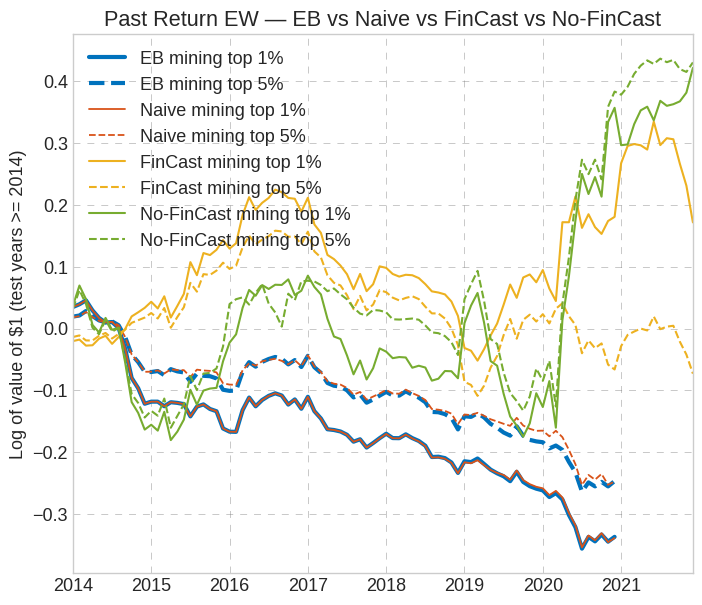


✅ Đã lưu biểu đồ: /content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/figs/beststrats-cret_PastReturnSignalsLongShort_ew.pdf


In [ ]:
# -*- coding: utf-8 -*-
"""
So sánh EB Mining / Naive Mining / FinCast Mining / No-FinCast Mining
CHỈ cho family: past_ret_ew (PastReturnSignalsLongShort_ew)
"""
import os, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import string
import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({"font.size": 13})
COLORS = ['#0072BD', '#D95319', '#EDB120', '#7E2F8E',
          '#77AC30', '#4DBEEE', '#A2142F']

# ============================================================
# 0. Config
# ============================================================
path_input = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/')
path_figs = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/figs/')
path_tables = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/tables/')
os.makedirs(path_figs, exist_ok=True)
os.makedirs(path_tables, exist_ok=True)

estimates_file = "hight_throughput_output/Nelly_Predict_SignalYear.csv.gzip"

FAMILY_RAW = 'PastReturnSignalsLongShort_ew'    # <-- ĐỔI: tên gốc khớp với FinCast/No-FinCast pipeline
FAMILY_SHORT = 'PastReturnSignalsLongShort_ew'                     #
FAMILY_LABEL = 'Past Return EW'                  # <-- ĐỔI: label hiển thị

ret_freq_adj = 12
oos_freq_adj = 1
YEAR_MIN = 1963
YEAR_MAX = 2020
TEST_YEAR_CUTOFF = 2014

FINCAST_PRED_PATH = (
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/'
    'results_per_family_pastret_ew/predictions_test_FinCast_PastReturnSignalsLongShort_ew.parquet'
)   # <-- ĐỔI thư mục + tên file cho khớp family mới
NOFINCAST_PRED_PATH = (
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/'
    'results_per_family_pastret_ew/predictions_test_V3_PastReturnSignalsLongShort_ew.parquet'
)   # <-- ĐỔI tương tự

SIGNAL_FAMILY_NAME_MAP = {
    "PastReturnSignalsLongShort_ew": "PastReturnSignalsLongShort_ew",   # <-- ĐỔI map cho family mới
}

# ============================================================
# 1. Load monthly returns — CHỈ family past_ret_ew
#    Khác DataMinedLongShortReturnsEW: file gốc là PastReturnSignalsLongShort.csv.gzip
#    có cột 'ret_ew' (không phải 'ret'), và cần lọc nshort>=2 & nlong>=2
# ============================================================
raw = pd.read_csv(path_input / 'StrategyReturns' / 'PastReturnSignalsLongShort.csv.gzip')
raw['date'] = pd.to_datetime(raw['date'])
raw['year'] = raw['date'].dt.year
if raw['date'].max().day != 1:
    raw['date'] = raw['date'] - pd.offsets.MonthBegin()
raw = raw.query('nshort>=2 & nlong>=2')

df = raw[['signalid', 'date', 'year', 'ret_ew']].rename(columns={'ret_ew': 'ret'}).sort_values(['signalid', 'date'])
df['signal_family'] = FAMILY_RAW
df_signal_ret = df.query('year>=@YEAR_MIN').copy()
df_signal_ret['signal_family'] = df_signal_ret['signal_family'].replace(SIGNAL_FAMILY_NAME_MAP)
df_signal_ret['signalid'] = df_signal_ret['signalid'].astype(str)

# ============================================================
# 2. Load estimates (IS tstat, EB pred_ret, thetahat, nobs) — lọc CHỈ past_ret_ew
# ============================================================
df_oos = df_signal_ret.rename(columns={'year': 'oos_begin_year'})

df_est = pd.read_csv(path_input / estimates_file)
df_est = df_est.rename(columns={'mean_ret': 'ret'}).drop(columns=['s_flag'])
df_est['signal_family'] = df_est['signal_family'].replace(SIGNAL_FAMILY_NAME_MAP)
df_est = df_est.query('signal_family == @FAMILY_SHORT').copy()
df_est['signalid'] = df_est['signalid'].astype(str)

cols = ['signal_family', 'signalid', 'date', 'oos_begin_year', 'ret']
df_est_oos = df_est.merge(df_oos[cols], how='inner', suffixes=('_is', '_oos'),
                           on=['signal_family', 'signalid', 'oos_begin_year'])
df_est_oos = df_est_oos.rename(columns={'tstat': 'tstat_is'})
print(f"df_est_oos (family={FAMILY_SHORT}): {len(df_est_oos)} dòng")

assert len(df_est_oos) > 0, (
    f"df_est_oos rỗng — kiểm tra lại: (1) SIGNAL_FAMILY_NAME_MAP có đúng tên trong "
    f"estimates_file không, (2) df_est có family '{FAMILY_SHORT}' không (thử: "
    f"pd.read_csv(path_input/estimates_file)['signal_family'].unique())"
)

# ============================================================
# 3. Get best strategies based on predicted return (EB, Naive)
# ============================================================
cols = ['signal_family', 'signalid', 'date', 'pred_ret', 'ret_oos', 'thetahat',
        'tstat_is', 'nobs', 'oos_begin_year']
df_signed = df_est_oos.query('oos_begin_year<=@YEAR_MAX')[cols].copy()

####################
# Naive Mining — sign theo IS t-stat
####################
df_signed['sign_tstat'] = np.sign(df_signed['tstat_is'])
df_signed['tstat_is'] = df_signed['sign_tstat']*df_signed['tstat_is']
df_signed['ret_oos_tstat'] = df_signed['sign_tstat']*df_signed['ret_oos']
df_signed['rank_pct_tstat'] = df_signed.groupby('date')['tstat_is'].transform(
    lambda x: x.rank(pct=True)) * 100

####################
# EB Mining — sign theo EB prediction, rank theo Sharpe ratio dự đoán
####################
df_signed['sign'] = np.sign(df_signed['pred_ret'])
df_signed['pred_ret'] = df_signed['sign']*df_signed['pred_ret']
df_signed['ret_oos'] = df_signed['sign']*df_signed['ret_oos']
df_signed['thetahat'] = df_signed['sign']*df_signed['thetahat']
df_signed['SRahat'] = (df_signed['thetahat']/np.sqrt(df_signed['nobs'])) * np.sqrt(ret_freq_adj)
df_signed['rank_pct'] = df_signed.groupby('date')['SRahat'].transform(
    lambda x: x.rank(pct=True)) * 100

extreme_ranks = [1, 5, 10]
df_best_ret = []
for sort_var, sfx in [('SRahat', ''), ('tstat_is', '_tstat')]:
    for rank in extreme_ranks:
        d = df_signed.loc[df_signed[f'rank_pct{sfx}'] >= 100-rank,
                           ['date', f'ret_oos{sfx}']].copy()
        d['ret_oos'] = d[f'ret_oos{sfx}']
        d = d.groupby('date').agg(ret_oos=('ret_oos', 'mean'),
                                   nstrat=('ret_oos', 'count')).reset_index()
        d['pctmin'] = rank
        d['sort_var'] = sort_var
        df_best_ret.append(d)
df_best_ret = pd.concat(df_best_ret)

# ============================================================
# 4. FinCast Mining & No-FinCast Mining
# ============================================================
def build_lstm_best_ret(pred_path, pred_col, sort_var_name, df_est_oos, extreme_ranks, test_year_cutoff):
    df_pred = pd.read_parquet(pred_path)
    df_pred['signalid'] = df_pred['signalid'].astype(str)
    fam_in_pred = df_pred['signal_family'].iloc[0]
    df_est_oos_use = df_est_oos.copy()
    if fam_in_pred != df_est_oos_use['signal_family'].iloc[0]:
        df_est_oos_use['signal_family'] = fam_in_pred

    df_est_oos_lstm = df_est_oos_use.merge(
        df_pred[['signal_family', 'signalid', 'oos_begin_year', pred_col]],
        how='inner', on=['signal_family', 'signalid', 'oos_begin_year']
    )
    df_est_oos_lstm = df_est_oos_lstm.query('oos_begin_year >= @test_year_cutoff').copy()
    print(f"  [{sort_var_name}] merged rows: {len(df_est_oos_lstm)}")

    df_est_oos_lstm['sign_lstm'] = np.sign(df_est_oos_lstm[pred_col])
    df_est_oos_lstm['ret_oos_lstm'] = df_est_oos_lstm['sign_lstm'] * df_est_oos_lstm['ret_oos']
    df_est_oos_lstm['rank_pct_lstm'] = df_est_oos_lstm.groupby('date')[pred_col].transform(
        lambda x: x.abs().rank(pct=True)) * 100

    out = []
    for rank in extreme_ranks:
        d = df_est_oos_lstm.loc[df_est_oos_lstm['rank_pct_lstm'] >= 100 - rank,
                                 ['date', 'ret_oos_lstm']].copy()
        d = d.rename(columns={'ret_oos_lstm': 'ret_oos'})
        d = d.groupby('date').agg(ret_oos=('ret_oos', 'mean'),
                                   nstrat=('ret_oos', 'count')).reset_index()
        d['pctmin'] = rank
        d['sort_var'] = sort_var_name
        out.append(d)
    return pd.concat(out)

print("Đang build FinCast Mining...")
df_best_ret_fincast = build_lstm_best_ret(
    FINCAST_PRED_PATH, 'pred_ret_fincast', 'pred_fincast',
    df_est_oos, extreme_ranks, TEST_YEAR_CUTOFF
)
print("Đang build No-FinCast Mining...")
df_best_ret_nofincast = build_lstm_best_ret(
    NOFINCAST_PRED_PATH, 'pred_ret_V3', 'pred_nofincast',
    df_est_oos, extreme_ranks, TEST_YEAR_CUTOFF
)

df_best_ret_eb_naive_test = df_best_ret.merge(
    df_signed[['date', 'oos_begin_year']].drop_duplicates(), on='date', how='left'
).query('oos_begin_year >= @TEST_YEAR_CUTOFF').drop(columns=['oos_begin_year'])

df_best_ret_all = pd.concat([
    df_best_ret_eb_naive_test,
    df_best_ret_fincast,
    df_best_ret_nofincast,
])

# ============================================================
# 5. Bảng tổng hợp: mean return, t-stat, Sharpe ratio
# ============================================================
sorting_types = [
    ('SRahat', 'EB Mining'),
    ('tstat_is', 'Naive Mining'),
    ('pred_fincast', 'FinCast Mining'),
    ('pred_nofincast', 'No-FinCast Mining'),
]
best_sumr = df_best_ret_all.copy()
for typ, lab in sorting_types:
    mask = best_sumr['sort_var'] == typ
    best_sumr.loc[mask, 'pctmin'] = best_sumr.loc[mask, 'pctmin'].replace(
        {1: f'{lab} Top 1%', 5: f'{lab} Top 5%', 10: f'{lab} Top 10%'})
best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos': 'ret'})
best_sumr['year'] = best_sumr['date'].dt.year

row_order = {
    'SRahat': ['EB Mining Top 1%', 'EB Mining Top 5%', 'EB Mining Top 10%'],
    'tstat_is': ['Naive Mining Top 1%', 'Naive Mining Top 5%', 'Naive Mining Top 10%'],
    'pred_fincast': ['FinCast Mining Top 1%', 'FinCast Mining Top 5%', 'FinCast Mining Top 10%'],
    'pred_nofincast': ['No-FinCast Mining Top 1%', 'No-FinCast Mining Top 5%', 'No-FinCast Mining Top 10%'],
}
sort_var_ls = ['SRahat', 'tstat_is', 'pred_fincast', 'pred_nofincast']
alphabets = string.ascii_uppercase

tabdat = []
for i, sort_var in enumerate(sort_var_ls):
    d = best_sumr.query("sort_var==@sort_var")
    d = d.groupby(["name"]).agg({
        'ret': ['mean', 'std', 'count'],
        'nstrat': 'mean'}
    )
    d.columns = [f'{c0}_{c1}' for c0, c1 in d.columns]
    d['sr'] = d.eval('ret_mean/ret_std')
    d['tstat'] = d.eval('ret_mean/ret_std*sqrt(ret_count)')
    d = d.drop(columns=['ret_std', 'ret_count'])
    d = d[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
    d = d.loc[row_order[sort_var]]
    line = pd.DataFrame(index=[f'Panel {alphabets[i]}'], columns=d.columns)
    d = pd.concat([line, d])
    d.loc[''] = np.nan
    tabdat.append(d)
tabdat = pd.concat(tabdat).iloc[:-1]

tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

cols = ['ret_mean', 'tstat', 'sr']
tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}' if pd.notnull(x) else '')
tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}' if pd.notnull(x) else '')
tabdat = tabdat.replace({'nan': ''})

print(f"\n=== Bảng so sánh — family: {FAMILY_LABEL}, test years >= {TEST_YEAR_CUTOFF} ===")
print(tabdat)

tabdat_export = tabdat.rename(
    columns={'nstrat_mean': '\\makecell{Num Strats \\\\ Combined}',
             'ret_mean': '\\makecell{Mean Return \\\\ (\\% ann)}',
             'tstat': '$t$-stat', 'sr': '\\makecell{Sharpe Ratio \\\\ (ann)}'})
col_format = 'l' + 'c' * tabdat_export.shape[1]
latex_table = tabdat_export.style.to_latex(column_format=col_format, hrules=True)

part = r'\\\\\n &  &  &  &'
repl = r'\\\\\n\\hline\n &  &  &  &'
latex_tableF = re.sub(part, repl, latex_table)
part = r'(\nPanel [A-Z] &  &  &  &  \\\\\n)'
repl = r'\1\\hline\n'
latex_tableF = re.sub(part, repl, latex_tableF)

with open(path_tables / f'beststrats_{FAMILY_SHORT}.tex', 'w') as fh:
    fh.write(latex_tableF)
print(f"\n✅ Đã lưu bảng LaTeX: {path_tables / f'beststrats_{FAMILY_SHORT}.tex'}")

# ============================================================
# 6. Biểu đồ cumulative return
# ============================================================
extreme_ranks_plot = [1, 5]
df_plot = df_best_ret_all.query('pctmin in @extreme_ranks_plot').copy()

label_map = {
    'SRahat': {1: 'EB mining top 1%', 5: 'EB mining top 5%'},
    'tstat_is': {1: 'Naive mining top 1%', 5: 'Naive mining top 5%'},
    'pred_fincast': {1: 'FinCast mining top 1%', 5: 'FinCast mining top 5%'},
    'pred_nofincast': {1: 'No-FinCast mining top 1%', 5: 'No-FinCast mining top 5%'},
}
for typ, mapping in label_map.items():
    mask = df_plot['sort_var'] == typ
    df_plot.loc[mask, 'pctmin'] = df_plot.loc[mask, 'pctmin'].replace(mapping)

df_plot = df_plot.pivot(columns=['sort_var', 'pctmin'], index='date', values='ret_oos').sort_index()
df_plot = (1 + df_plot / 100).cumprod()

color_dic = {
    'SRahat': (COLORS[0], 3),
    'tstat_is': (COLORS[1], 1.3),
    'pred_fincast': (COLORS[2], 1.5),
    'pred_nofincast': (COLORS[4], 1.5),
}

fig, ax = plt.subplots(figsize=(8, 7))
for typ, params in color_dic.items():
    clr, lwidth = params
    if typ not in df_plot.columns.get_level_values(0):
        continue
    temp = np.log(df_plot[typ])
    temp.plot(ax=ax, color=[clr, clr], style=['-', '--'], linewidth=lwidth)

plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)
ax.set_ylabel(f'Log of value of $1 (test years >= {TEST_YEAR_CUTOFF})')
ax.set_xlabel('')
ax.set_title(f'{FAMILY_LABEL} — EB vs Naive vs FinCast vs No-FinCast')
plt.legend(loc='upper left', alignment='left')
fig.savefig(path_figs / f'beststrats-cret_{FAMILY_SHORT}.pdf', format='pdf', bbox_inches="tight")
plt.show()

print(f"\n✅ Đã lưu biểu đồ: {path_figs / f'beststrats-cret_{FAMILY_SHORT}.pdf'}")

# acct vw

In [ ]:
#fincast+lstm+att
import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr
from huggingface_hub import hf_hub_download

# ============================================================
# 0. Config — CHỈ 1 FAMILY
# ============================================================
FAMILY = 'DataMinedLongShortReturnsVW'   # <-- ĐỔI từ 'DataMinedLongShortReturnsEW'
KEYS_DIR = '/content/fincast_embeddings'
REPO_ID = "ngandh/fincast-embeddings"
REPO_TYPE = "dataset"

rollsignal_path = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
ROLLSIGNAL_USECOLS = ['signalid', 'signal_family', 's_flag', 'oos_begin_year', 'tstat', 'mean_ret']

RESULTS_DIR = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_acctVW'  # <-- ĐỔI thư mục, tránh ghi đè EW
os.makedirs(RESULTS_DIR, exist_ok=True)

VAL_YEAR_CUTOFF = 2011
TEST_YEAR_CUTOFF = 2014

# ============================================================
# 1. Tải hidden (.npy) + keys (.parquet) cho ĐÚNG 1 family
# ============================================================
hidden_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=f"fincast_hidden_{FAMILY}.npy",   # tự đổi theo FAMILY
    repo_type=REPO_TYPE,
    token=hf_token,
)
keys_path = f'/content/fincast_keys_{FAMILY}.parquet'   # <-- ĐỔI: tự đổi theo FAMILY
assert os.path.exists(keys_path), f"Không tìm thấy {keys_path} — cần tải/copy file keys cho family {FAMILY} trước"

print(f"hidden_path: {hidden_path}")
print(f"keys_path:   {keys_path}")

hidden_arr = np.load(hidden_path, mmap_mode='r')
print("hidden_arr shape:", hidden_arr.shape)

fincast_hidden_DataMinedLongShortReturns(…): reconstructing file:   0%|          |  0.00B / 21.2GB            

fincast_hidden_DataMinedLongShortReturns(…): downloading bytes:           |  0.00B            

hidden_path: /root/.cache/huggingface/hub/datasets--ngandh--fincast-embeddings/snapshots/2214269a23d64b63c1db6536540f1f20bd13af89/fincast_hidden_DataMinedLongShortReturnsVW.npy
keys_path:   /content/fincast_keys_DataMinedLongShortReturnsVW.parquet
hidden_arr shape: (1033882, 4, 1280)


In [ ]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import spearmanr

# ============================================================
# 0. Reproducibility — FIX #4
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ⚠️ Kiểm tra ngay đầu: biến FAMILY, RESULTS_DIR, keys_path, hidden_arr phải đã tồn tại
# và khớp với family VW (được set ở cell "1. Tải hidden + keys" trước đó)
assert 'FAMILY' in dir(), "Biến FAMILY chưa được định nghĩa — chạy lại cell load hidden_arr/keys_path trước"
assert FAMILY == 'DataMinedLongShortReturnsVW', \
    f"FAMILY hiện tại = '{FAMILY}', không khớp với VW — kiểm tra lại cell trước đó"
print(f"✅ Đang train cho FAMILY = {FAMILY}")
print(f"✅ RESULTS_DIR = {RESULTS_DIR}")
print(f"✅ hidden_arr shape = {hidden_arr.shape}")

# ============================================================
# 2. Merge rollsignal (IS/OOS) với keys — CHỈ 1 FAMILY
# ============================================================
def join_rollsignal_with_sequence(rollsignal_path, keys_path):
    rollsignal = pd.read_csv(rollsignal_path, usecols=ROLLSIGNAL_USECOLS)
    rollsignal['signalid'] = rollsignal['signalid'].astype(str)
    rollsignal['tstat'] = rollsignal['tstat'].astype(np.float32)
    rollsignal['mean_ret'] = rollsignal['mean_ret'].astype(np.float32)

    is_df = rollsignal[rollsignal['s_flag'] == 'IS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'tstat', 'mean_ret']
    ].rename(columns={'tstat': 'tstat_IS', 'mean_ret': 'mean_ret_IS'})

    oos_df = rollsignal[rollsignal['s_flag'] == 'OOS'][
        ['signalid', 'signal_family', 'oos_begin_year', 'mean_ret']
    ].rename(columns={'mean_ret': 'mean_ret_OOS'})

    del rollsignal
    gc.collect()

    keys_df = pd.read_parquet(keys_path)
    keys_df['signalid'] = keys_df['signalid'].astype(str)
    if 'emb_idx' not in keys_df.columns:
        keys_df['emb_idx'] = np.arange(len(keys_df), dtype=np.int32)

    dup_keys = keys_df.duplicated(subset=['signalid', 'signal_family', 'oos_begin_year']).sum()
    assert dup_keys == 0, f"keys_df có {dup_keys} dòng key bị trùng lặp — kiểm tra lại file extraction"
    assert keys_df['emb_idx'].is_unique, "emb_idx trong keys_df không unique"

    fam = keys_df['signal_family'].iloc[0] if len(keys_df) > 0 else None
    is_df_fam = is_df[is_df['signal_family'] == fam] if fam else is_df
    print(f"[Chẩn đoán] Family trong keys_df: {sorted(keys_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Family trong is_df (rollsignal, IS): {sorted(is_df['signal_family'].unique())}")
    print(f"[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): {len(is_df_fam)}")
    print(f"[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    {len(keys_df)}")
    print(f"[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: "
          f"{len(keys_df) / max(len(is_df_fam), 1) * 100:.1f}%")

    is_df = is_df.merge(
        keys_df[['signalid', 'signal_family', 'oos_begin_year', 'emb_idx']],
        on=['signalid', 'signal_family', 'oos_begin_year'], how='left'
    )
    n_matched = is_df['emb_idx'].notna().sum()
    print(f"Matched: {n_matched}/{len(is_df)} ({n_matched/len(is_df)*100:.1f}%)")

    del keys_df
    gc.collect()
    return is_df, oos_df

is_df, oos_df = join_rollsignal_with_sequence(rollsignal_path, keys_path)
merged = is_df.merge(oos_df, on=['signalid', 'signal_family', 'oos_begin_year'], how='inner')
del is_df, oos_df
gc.collect()

merged = merged.dropna(subset=['emb_idx', 'tstat_IS', 'mean_ret_IS', 'mean_ret_OOS'])
merged['emb_idx'] = merged['emb_idx'].astype(np.int32)

dup_merged = merged['emb_idx'].duplicated().sum()
assert dup_merged == 0, f"merged có {dup_merged} dòng emb_idx bị trùng lặp — kiểm tra lại merge key"

print("Số signal-window:", len(merged))
print(merged['signal_family'].value_counts())

# ⚠️ đảm bảo merged chỉ chứa đúng family VW, tránh lẫn với EW nếu keys_path bị nhầm
assert merged['signal_family'].nunique() == 1, "merged chứa nhiều hơn 1 family — kiểm tra lại keys_path"
assert merged['signal_family'].iloc[0] == FAMILY, \
    f"merged['signal_family']='{merged['signal_family'].iloc[0]}' không khớp FAMILY='{FAMILY}'"

# ============================================================
# 3. Model, metrics, batch iterator (streaming) — KHÔNG ĐỔI
# ============================================================
class LSTMAttentionRegressor(nn.Module):
    def __init__(self, seq_input_dim=1280, extra_feat_dim=2, lstm_hidden=128, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=seq_input_dim, hidden_size=lstm_hidden, num_layers=1,
            batch_first=True, bidirectional=True,
        )
        lstm_out_dim = lstm_hidden * 2
        self.attn_proj = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_v = nn.Linear(lstm_out_dim, 1, bias=False)
        head_in = lstm_out_dim + extra_feat_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, seq, extra_feats):
        lstm_out, _ = self.lstm(seq)
        scores = self.attn_v(torch.tanh(self.attn_proj(lstm_out))).squeeze(-1)
        attn_weights = torch.softmax(scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1)
        combined = torch.cat([context, extra_feats], dim=1)
        pred = self.head(combined).squeeze(-1)
        return pred, attn_weights


def compute_scaler_stats_streaming(hidden_arr, idx_array, batch_size=50000):
    D = hidden_arr.shape[2]
    sum_ = np.zeros(D, dtype=np.float64)
    sum_sq = np.zeros(D, dtype=np.float64)
    count = 0
    n = len(idx_array)
    idx_sorted = np.sort(idx_array)
    for i in range(0, n, batch_size):
        batch_idx = idx_sorted[i:i+batch_size]
        chunk = np.asarray(hidden_arr[batch_idx]).reshape(-1, D)
        sum_ += chunk.sum(axis=0)
        sum_sq += (chunk.astype(np.float64) ** 2).sum(axis=0)
        count += chunk.shape[0]
    mean = sum_ / count
    std = np.sqrt(sum_sq / count - mean ** 2)
    return mean.astype(np.float32), std.astype(np.float32)


def iterate_batches_streaming(idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                               batch_size, shuffle=True, device='cuda'):
    n = len(idx_array)
    order = np.random.permutation(n) if shuffle else np.arange(n)
    for start in range(0, n, batch_size):
        batch_order = order[start:start + batch_size]
        emb_ids = idx_array[batch_order]
        sort_order = np.argsort(emb_ids)
        emb_ids_sorted = emb_ids[sort_order]
        seq_b = np.asarray(hidden_arr[emb_ids_sorted])
        seq_b = (seq_b - mean_) / (std_ + 1e-8)
        seq_b = torch.from_numpy(seq_b.astype(np.float32))
        feat_b = torch.from_numpy(feat_arr[batch_order][sort_order].astype(np.float32))
        yb = torch.from_numpy(y_arr[batch_order][sort_order].astype(np.float32))
        if device != 'cpu':
            seq_b = seq_b.to(device, non_blocking=True)
            feat_b = feat_b.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
        yield seq_b, feat_b, yb


def eval_streaming_ordered(model, idx_array, feat_arr, y_arr, hidden_arr, mean_, std_,
                            batch_size, device):
    model.eval()
    all_pred, all_true, all_idx = [], [], []
    n = len(idx_array)
    order = np.arange(n)
    with torch.no_grad():
        for start in range(0, n, batch_size):
            batch_order = order[start:start + batch_size]
            emb_ids = idx_array[batch_order]
            sort_order = np.argsort(emb_ids)
            emb_ids_sorted = emb_ids[sort_order]
            seq_b = np.asarray(hidden_arr[emb_ids_sorted])
            seq_b = (seq_b - mean_) / (std_ + 1e-8)
            seq_b = torch.from_numpy(seq_b.astype(np.float32)).to(device)
            feat_b = torch.from_numpy(
                feat_arr[batch_order][sort_order].astype(np.float32)
            ).to(device)
            y_b = y_arr[batch_order][sort_order]
            pred_b, _ = model(seq_b, feat_b)
            all_pred.append(pred_b.cpu().numpy())
            all_true.append(y_b)
            all_idx.append(emb_ids_sorted)
    pred_final = np.concatenate(all_pred)
    y_final = np.concatenate(all_true)
    idx_final = np.concatenate(all_idx)
    return pred_final, y_final, idx_final


def compute_regression_metrics(y_true, y_pred, prefix=''):
    y_true_sign = (y_true > 0).astype(int)
    y_pred_sign = (y_pred > 0).astype(int)
    return {
        f'{prefix}mse': float(np.mean((y_pred - y_true) ** 2)),
        f'{prefix}mae': float(mean_absolute_error(y_true, y_pred)),
        f'{prefix}r2': float(r2_score(y_true, y_pred)),
        f'{prefix}dir_acc': float(accuracy_score(y_true_sign, y_pred_sign)),
        f'{prefix}precision': float(precision_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}recall': float(recall_score(y_true_sign, y_pred_sign, zero_division=0)),
        f'{prefix}f1': float(f1_score(y_true_sign, y_pred_sign, zero_division=0)),
    }


def portfolio_relevant_report_yearly(y_true, y_pred, oos_years, n_deciles=10):
    df = pd.DataFrame({'year': oos_years, 'y_true': y_true, 'y_pred': y_pred})
    ic_rows = []
    for yr, g in df.groupby('year'):
        if len(g) < 5:
            continue
        ic_yr, _ = spearmanr(g['y_pred'], g['y_true'])
        ic_rows.append({'oos_begin_year': yr, 'n': len(g), 'IC': ic_yr})
    ic_by_year_df = pd.DataFrame(ic_rows).sort_values('oos_begin_year')
    ic_mean = ic_by_year_df['IC'].mean()
    ic_std = ic_by_year_df['IC'].std()
    print(f"\nMean yearly IC: {ic_mean:.4f} (std={ic_std:.4f}, n_years={len(ic_by_year_df)})")
    print(ic_by_year_df.to_string(index=False))

    decile_rows = []
    for yr, g in df.groupby('year'):
        g = g.copy()
        try:
            g['decile'] = pd.qcut(g['y_pred'], n_deciles, labels=np.arange(1, n_deciles + 1))
        except ValueError:
            continue
        for d, sub in g.groupby('decile', observed=True):
            decile_rows.append({
                'year': yr, 'decile': int(d), 'n': len(sub),
                'mean_pred': sub['y_pred'].mean(),
                'mean_actual_ret': sub['y_true'].mean(),
            })
    decile_by_year_df = pd.DataFrame(decile_rows)

    decile_agg = decile_by_year_df.groupby('decile').agg(
        n=('n', 'sum'),
        mean_pred=('mean_pred', 'mean'),
        mean_actual_ret=('mean_actual_ret', 'mean'),
    ).reset_index()
    print("\nDecile spread (trung bình các năm, KHÔNG pooled):")
    print(decile_agg.to_string(index=False))

    is_monotonic = decile_agg['mean_actual_ret'].is_monotonic_increasing
    ls_by_year = decile_by_year_df.pivot(index='year', columns='decile', values='mean_actual_ret')
    ls_spread_by_year = ls_by_year[n_deciles] - ls_by_year[1]
    ls_spread_mean = ls_spread_by_year.mean()
    ls_spread_tstat = ls_spread_mean / ls_spread_by_year.std() * np.sqrt(len(ls_spread_by_year))
    print(f"\nLong-short spread (trung bình theo năm): {ls_spread_mean:.4f}, "
          f"t-stat: {ls_spread_tstat:.4f}")

    return {
        'ic_by_year': ic_by_year_df, 'ic_mean': float(ic_mean), 'ic_std': float(ic_std),
        'decile_by_year': decile_by_year_df, 'decile_agg': decile_agg,
        'is_monotonic': bool(is_monotonic),
        'long_short_spread_by_year': ls_spread_by_year,
        'long_short_spread_mean': float(ls_spread_mean),
        'long_short_spread_tstat': float(ls_spread_tstat),
    }


# ============================================================
# 4. Train + eval streaming — KHÔNG ĐỔI LOGIC
# ============================================================
def train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100, lr=1e-3, seed=42,
    val_year_cutoff=VAL_YEAR_CUTOFF, test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path='training_log.csv',
    eval_every=5, batch_size=1024, device=None,
    early_stopping_patience=15,
    checkpoint_dir=None, checkpoint_every=5,
    scaler_batch_size=50000,
):
    set_seed(seed)
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Device: {device}, batch_size={batch_size}")

    emb_idx_all = merged['emb_idx'].to_numpy(dtype=np.int64)
    extra_feats_all = merged[['tstat_IS', 'mean_ret_IS']].to_numpy(dtype=np.float32)
    y_ret = merged['mean_ret_OOS'].to_numpy(dtype=np.float32)
    years_all = merged['oos_begin_year'].to_numpy()

    train_mask = years_all < val_year_cutoff
    val_mask   = (years_all >= val_year_cutoff) & (years_all < test_year_cutoff)
    test_mask  = years_all >= test_year_cutoff

    assert train_mask.sum() > 0, "Train set rỗng, kiểm tra lại val_year_cutoff"
    assert val_mask.sum()   > 0, "Validation set rỗng, kiểm tra lại val_year_cutoff/test_year_cutoff"
    assert test_mask.sum()  > 0, "Test set rỗng, kiểm tra lại test_year_cutoff"

    print(f"Split theo năm CỐ ĐỊNH: train < {val_year_cutoff} (n={train_mask.sum()}), "
          f"val [{val_year_cutoff}, {test_year_cutoff}) (n={val_mask.sum()}), "
          f"test >= {test_year_cutoff} (n={test_mask.sum()})")

    idx_train, idx_val, idx_test = emb_idx_all[train_mask], emb_idx_all[val_mask], emb_idx_all[test_mask]
    feat_train, feat_val, feat_test = extra_feats_all[train_mask], extra_feats_all[val_mask], extra_feats_all[test_mask]
    y_train, y_val, y_test = y_ret[train_mask], y_ret[val_mask], y_ret[test_mask]
    years_train, years_val, years_test = years_all[train_mask], years_all[val_mask], years_all[test_mask]

    del emb_idx_all, extra_feats_all, y_ret, years_all
    gc.collect()

    print("Đang tính mean/std của embedding (streaming, CHỈ trên train)...")
    mean_, std_ = compute_scaler_stats_streaming(hidden_arr, idx_train, batch_size=scaler_batch_size)

    feat_scaler = StandardScaler(copy=False)
    feat_train = feat_scaler.fit_transform(feat_train).astype(np.float32)
    feat_val   = feat_scaler.transform(feat_val).astype(np.float32)
    feat_test  = feat_scaler.transform(feat_test).astype(np.float32)

    D = hidden_arr.shape[2]
    model = LSTMAttentionRegressor(seq_input_dim=D, extra_feat_dim=feat_train.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    if checkpoint_dir is not None:
        os.makedirs(checkpoint_dir, exist_ok=True)
    best_ckpt_path = f'{checkpoint_dir}/best.pt' if checkpoint_dir else None
    last_ckpt_path = f'{checkpoint_dir}/last.pt' if checkpoint_dir else None

    history = []
    best_val_ic = -float('inf')
    best_state = None
    epochs_no_improve = 0

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss_sum, n_seen = 0.0, 0
        for seq_b, feat_b, yb in iterate_batches_streaming(
            idx_train, feat_train, y_train, hidden_arr, mean_, std_,
            batch_size=batch_size, shuffle=True, device=device,
        ):
            optimizer.zero_grad()
            pred, _ = model(seq_b, feat_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        train_mse_running = train_loss_sum / max(n_seen, 1)

        do_eval = (epoch + 1) % eval_every == 0 or epoch == epochs - 1
        if do_eval:
            model.eval()
            val_preds, val_trues = [], []
            with torch.no_grad():
                for seq_b, feat_b, yb in iterate_batches_streaming(
                    idx_val, feat_val, y_val, hidden_arr, mean_, std_,
                    batch_size=batch_size, shuffle=False, device=device,
                ):
                    pred, _ = model(seq_b, feat_b)
                    val_preds.append(pred.cpu().numpy())
                    val_trues.append(yb.cpu().numpy())
            val_pred_arr = np.concatenate(val_preds)
            val_true_arr = np.concatenate(val_trues)
            val_metrics = compute_regression_metrics(val_true_arr, val_pred_arr, prefix='val_')
            val_ic, _ = spearmanr(val_pred_arr, val_true_arr)
            val_ic = float(val_ic) if not np.isnan(val_ic) else -1.0
            val_metrics['val_ic'] = val_ic

            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE: {train_mse_running:.6f} | "
                  f"Val MSE: {val_metrics['val_mse']:.6f} | Val IC: {val_ic:.4f}")
            history.append({'epoch': epoch+1, 'train_mse_running': train_mse_running, **val_metrics})

            if val_ic > best_val_ic + 1e-8:
                best_val_ic = val_ic
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_no_improve = 0
                if best_ckpt_path:
                    torch.save({'epoch': epoch+1, 'model_state': best_state, 'val_ic': best_val_ic}, best_ckpt_path)
            else:
                epochs_no_improve += eval_every
                if epochs_no_improve >= early_stopping_patience:
                    print(f"⏹ Early stopping tại epoch {epoch+1}")
                    break
        else:
            dt = time.time() - t0
            print(f"Epoch {epoch+1}/{epochs} ({dt:.1f}s) | Train MSE (running): {train_mse_running:.6f}")

        if last_ckpt_path and ((epoch+1) % checkpoint_every == 0 or epoch == epochs-1):
            torch.save({'epoch': epoch+1, 'model_state': model.state_dict(),
                        'optimizer_state': optimizer.state_dict(), 'history': history}, last_ckpt_path)

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"✅ Khôi phục best model (val_IC={best_val_ic:.4f})")

    history_df = pd.DataFrame(history)
    history_df.to_csv(log_path, index=False)

    pred_nn, y_test_ordered, idx_test_ordered = eval_streaming_ordered(
        model, idx_test, feat_test, y_test, hidden_arr, mean_, std_,
        batch_size=batch_size, device=device,
    )

    idx_to_year = dict(zip(idx_test, years_test))
    years_test_ordered = np.array([idx_to_year[i] for i in idx_test_ordered])

    portfolio_report = portfolio_relevant_report_yearly(y_test_ordered, pred_nn, oos_years=years_test_ordered)

    results = {
        'pred_nn': pred_nn,
        'y_test': y_test_ordered,
        'years_test': years_test_ordered,
        'idx_test': idx_test_ordered,
        'best_val_ic': best_val_ic,
        'val_year_cutoff': val_year_cutoff,
        'test_year_cutoff': test_year_cutoff,
    }
    return model, mean_, std_, feat_scaler, results, history_df, portfolio_report


# ============================================================
# 5. Chạy train — FAMILY = DataMinedLongShortReturnsVW
# ============================================================
fam_log_path = f'{RESULTS_DIR}/log_{FAMILY}.csv'
fam_ckpt_dir = f'/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/checkpoints_{FAMILY}'

model, mean_, std_, feat_scaler, results, history_df, portfolio_report = train_and_eval_streaming(
    merged, hidden_arr,
    epochs=100,
    batch_size=1024,
    val_year_cutoff=VAL_YEAR_CUTOFF,
    test_year_cutoff=TEST_YEAR_CUTOFF,
    log_path=fam_log_path,
    checkpoint_dir=fam_ckpt_dir,
    early_stopping_patience=15,
)

print(f"\n✅ Best validation IC (dùng để chọn checkpoint): {results['best_val_ic']:.4f}")
print(f"✅ Mean yearly test IC (đánh giá cuối cùng, không leak, không pooled): "
      f"{portfolio_report['ic_mean']:.4f}")

# ============================================================
# 6. Lưu predictions test kèm meta
# ============================================================
idx_test_ordered = results['idx_test']

test_meta = merged[merged['emb_idx'].isin(idx_test_ordered)][
    ['signal_family', 'signalid', 'oos_begin_year', 'emb_idx']
].copy()
assert test_meta['emb_idx'].is_unique, "emb_idx trong test_meta bị trùng — merge sai key"
test_meta['signalid'] = test_meta['signalid'].astype(str)

idx_to_pos = {v: i for i, v in enumerate(idx_test_ordered)}
test_meta['_pos'] = test_meta['emb_idx'].map(idx_to_pos)
test_meta = test_meta.sort_values('_pos').drop(columns=['_pos', 'emb_idx']).reset_index(drop=True)

assert len(test_meta) == len(results['pred_nn']), \
    f"Số dòng lệch: test_meta={len(test_meta)} vs pred_nn={len(results['pred_nn'])}"

test_meta['pred_ret_fincast'] = results['pred_nn']

pred_out_path = f'{RESULTS_DIR}/predictions_test_FinCast_{FAMILY}.parquet'
test_meta.to_parquet(pred_out_path, index=False)
print(f"✅ Đã lưu predictions FinCast: {pred_out_path}")
print(f"✅ Đã lưu checkpoint: {fam_ckpt_dir}/best.pt")

saved_check = pd.read_parquet(pred_out_path)
print(f"\nKiểm tra: tồn tại={os.path.exists(pred_out_path)}, shape={saved_check.shape}")

✅ Đang train cho FAMILY = DataMinedLongShortReturnsVW
✅ RESULTS_DIR = /content/drive/MyDrive/Nelly_KHMT2025/research/experiments/fincast/results_per_family_acctVW
✅ hidden_arr shape = (1033882, 4, 1280)
[Chẩn đoán] Family trong keys_df: ['DataMinedLongShortReturnsVW']
[Chẩn đoán] Family trong is_df (rollsignal, IS): ['DataMinedLongShortReturnsEW', 'DataMinedLongShortReturnsVW', 'PastReturnSignalsLongShort_ew', 'PastReturnSignalsLongShort_vw', 'TickerSignalsLongShort_ew', 'TickerSignalsLongShort_vw']
[Chẩn đoán] Số dòng is_df (toàn bộ family có trong rollsignal): 1005558
[Chẩn đoán] Số dòng keys_df (đã extract FinCast embedding):    1033882
[Chẩn đoán] Tỷ lệ đã extract / tổng cần có: 102.8%
Matched: 979356/5113700 (19.2%)
Số signal-window: 979356
signal_family
DataMinedLongShortReturnsVW    979356
Name: count, dtype: int64
Device: cuda, batch_size=1024
Split theo năm CỐ ĐỊNH: train < 2011 (n=692423), val [2011, 2014) (n=79133), test >= 2014 (n=207800)
Đang tính mean/std của embedding (s

# new version to submit

In [ ]:
import pandas as pd
import numpy as np

# ==== 1. CHỈNH ĐƯỜNG DẪN FILE Ở ĐÂY ====
FILE_PATH = "/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedLongShortReturnsEW.csv"   # hoặc .parquet, .dta...

# Nếu file quá lớn, đọc thử với parquet (nhanh & nhẹ hơn) hoặc dùng nrows để test trước
# df = pd.read_csv(FILE_PATH, nrows=100000)   # test nhanh với 100k dòng đầu
df = pd.read_csv(FILE_PATH)   # nếu máy đủ RAM thì đọc full

print("="*60)
print("1. KÍCH THƯỚC & CỘT")
print("="*60)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Dtypes:\n", df.dtypes)

print("\n" + "="*60)
print("2. SỐ LƯỢNG SIGNAL & PHẠM VI THỜI GIAN")
print("="*60)
print("Số signal unique:", df['signalid'].nunique())
print("Năm min-max:", df['year'].min(), "-", df['year'].max())
print("Tổng số tháng-quan sát:", len(df))

print("\n" + "="*60)
print("3. MISSING VALUES")
print("="*60)
print(df.isnull().sum())

print("\n" + "="*60)
print("4. THỐNG KÊ RET & NSTOCK")
print("="*60)
print(df[['ret', 'nstock']].describe())

print("\n5% và 95% percentile của ret:")
print(df['ret'].quantile([0.01, 0.05, 0.5, 0.95, 0.99]))

print("\n" + "="*60)
print("5. ĐỘ DÀI CHUỖI THEO TỪNG SIGNAL (số tháng có dữ liệu)")
print("="*60)
signal_lengths = df.groupby('signalid').size()
print(signal_lengths.describe())
print("\nSố signal có >= 61 tháng dữ liệu (đủ cho window 60 input + 1 target):")
print((signal_lengths >= 61).sum(), "/", len(signal_lengths))

print("\n" + "="*60)
print("6. KIỂM TRA GAP THÁNG (signal có thiếu tháng ở giữa không)")
print("="*60)
def check_gaps(g):
    g = g.sort_values(['year','month'])
    t = g['year']*12 + g['month']
    diffs = t.diff().dropna()
    return (diffs != 1).sum()  # đếm số chỗ bị gap

# Cảnh báo: chạy dòng dưới có thể chậm nếu quá nhiều signal, có thể sample trước
sample_ids = df['signalid'].drop_duplicates().sample(min(500, df['signalid'].nunique()), random_state=42)
gap_counts = df[df['signalid'].isin(sample_ids)].groupby('signalid').apply(check_gaps)
print("Trong mẫu 500 signal, số signal có ít nhất 1 gap:", (gap_counts > 0).sum())
print("Trung bình số gap mỗi signal (trong mẫu):", gap_counts.mean())

print("\n" + "="*60)
print("7. XEM 5 DÒNG ĐẦU & CUỐI")
print("="*60)
print(df.head())
print(df.tail())

print("\n" + "="*60)
print("8. KIỂM TRA CỘT FAMILY (nếu có) - xác nhận đúng Acct EW")
print("="*60)
possible_family_cols = [c for c in df.columns if 'fam' in c.lower() or 'sign' in c.lower() or 'weight' in c.lower()]
print("Các cột có thể liên quan family/weighting:", possible_family_cols)

1. KÍCH THƯỚC & CỘT
Shape: (16941504, 5)
Columns: ['signalid', 'year', 'month', 'ret', 'nstock']
Dtypes:
 signalid      int64
year          int64
month         int64
ret         float64
nstock        int64
dtype: object

2. SỐ LƯỢNG SIGNAL & PHẠM VI THỜI GIAN
Số signal unique: 29314
Năm min-max: 1951 - 2022
Tổng số tháng-quan sát: 16941504

3. MISSING VALUES
signalid    0
year        0
month       0
ret         0
nstock      0
dtype: int64

4. THỐNG KÊ RET & NSTOCK
                ret        nstock
count  1.694150e+07  1.694150e+07
mean  -1.073492e-01  9.288226e+02
std    3.504183e+00  1.072784e+03
min   -2.967768e+02  2.000000e+00
25%   -1.486953e+00  2.780000e+02
50%   -6.417303e-02  5.540000e+02
75%    1.337186e+00  9.460000e+02
max    2.283079e+02  7.573000e+03

5% và 95% percentile của ret:
0.01   -9.682151
0.05   -4.657638
0.50   -0.064173
0.95    4.348597
0.99    8.715269
Name: ret, dtype: float64

5. ĐỘ DÀI CHUỖI THEO TỪNG SIGNAL (số tháng có dữ liệu)
count    29314.000000
mean

/tmp/ipykernel_1020/811638281.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gap_counts = df[df['signalid'].isin(sample_ids)].groupby('signalid').apply(check_gaps)


In [ ]:
import pandas as pd
import numpy as np

FILE_PATH = "/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedLongShortReturnsEW.csv"
df = pd.read_csv(FILE_PATH)

print("="*60)
print("1. OUTLIER EXTREMES - liên hệ với nstock")
print("="*60)
extreme = df[(df['ret'].abs() > 50)]
print("Số dòng |ret| > 50%:", len(extreme), f"({len(extreme)/len(df)*100:.3f}%)")
print(extreme[['nstock']].describe())
print("\nSo sánh nstock toàn bộ vs nstock của outlier:")
print("Toàn bộ - median nstock:", df['nstock'].median())
print("Outlier - median nstock:", extreme['nstock'].median())

print("\n" + "="*60)
print("2. PHÂN BỐ NĂM BẮT ĐẦU CỦA MỖI SIGNAL")
print("="*60)
start_years = df.groupby('signalid')['year'].min()
print(start_years.value_counts().sort_index().head(20))
print("...")
print("Số signal bắt đầu trước 1963:", (start_years < 1963).sum())

print("\n" + "="*60)
print("3. PHÂN BỐ NĂM KẾT THÚC CỦA MỖI SIGNAL")
print("="*60)
end_years = df.groupby('signalid')['year'].max()
print(end_years.value_counts().sort_index().tail(10))

print("\n" + "="*60)
print("4. NSTOCK THEO THỜI GIAN (kiểm tra early years có noisy không)")
print("="*60)
nstock_by_year = df.groupby('year')['nstock'].median()
print(nstock_by_year.head(15))
print("...")
print(nstock_by_year.tail(10))

print("\n" + "="*60)
print("5. SỐ SIGNAL CÓ DỮ LIỆU TRONG MỖI NĂM (kiểm tra panel cân đối)")
print("="*60)
signals_per_year = df.groupby('year')['signalid'].nunique()
print(signals_per_year)

print("\n" + "="*60)
print("6. KIỂM TRA GAP CHI TIẾT HƠN (full, không sample)")
print("="*60)
def check_gap_detail(g):
    g = g.sort_values(['year','month'])
    t = g['year'].values*12 + g['month'].values
    diffs = np.diff(t)
    n_gaps = (diffs != 1).sum()
    max_gap = diffs.max() - 1 if len(diffs) > 0 else 0
    return pd.Series({'n_gaps': n_gaps, 'max_gap_months': max_gap})

# Full check (có thể mất vài phút với 29k signal)
gap_stats = df.groupby('signalid', group_keys=False).apply(check_gap_detail, include_groups=False)
print(gap_stats.describe())
print("\nSố signal có gap > 3 tháng liên tục:", (gap_stats['max_gap_months'] > 3).sum())

1. OUTLIER EXTREMES - liên hệ với nstock
Số dòng |ret| > 50%: 3492 (0.021%)
            nstock
count  3492.000000
mean    338.836770
std     951.984333
min       2.000000
25%       2.000000
50%       3.000000
75%      12.000000
max    5043.000000

So sánh nstock toàn bộ vs nstock của outlier:
Toàn bộ - median nstock: 554.0
Outlier - median nstock: 3.0

2. PHÂN BỐ NĂM BẮT ĐẦU CỦA MỖI SIGNAL
year
1951    2048
1952    3894
1953     235
1954     126
1955     111
1956      63
1957       3
1958       9
1959      12
1960      13
1961      10
1962     762
1963    1634
1964     649
1965     173
1966     390
1967     298
1968     213
1969     106
1970    1834
Name: count, dtype: int64
...
Số signal bắt đầu trước 1963: 7286

3. PHÂN BỐ NĂM KẾT THÚC CỦA MỖI SIGNAL
year
2013       91
2014      275
2015        2
2016        3
2017        1
2018       44
2019       20
2020       18
2021       87
2022    26055
Name: count, dtype: int64

4. NSTOCK THEO THỜI GIAN (kiểm tra early years có noisy không)
ye

In [ ]:
import pandas as pd
import numpy as np

FILE_PATH = "/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedLongShortReturnsEW.csv"
df = pd.read_csv(FILE_PATH)

# 1. Lọc theo năm và nstock
df = df[df['year'] >= 1963].copy()
df = df[df['nstock'] >= 10].copy()

# 2. Tạo cột thời gian liên tục (số tháng kể từ mốc) để phát hiện gap
df['t'] = df['year']*12 + df['month']
df = df.sort_values(['signalid', 't']).reset_index(drop=True)

# 3. Đánh dấu các đoạn liên tục (contiguous segment) trong mỗi signal
def mark_segments(g):
    diffs = g['t'].diff()
    new_seg = (diffs != 1).cumsum().fillna(0)
    g = g.copy()
    g['segment_id'] = new_seg.astype(int)
    return g

df = df.groupby('signalid', group_keys=False).apply(mark_segments, include_groups=False if False else True)
# Lưu ý: nếu pandas mới báo warning, dùng cách thủ công dưới đây thay thế:

# ---- Cách thủ công tránh warning (khuyến nghị) ----
df = df.sort_values(['signalid', 't']).reset_index(drop=True)
df['t_diff'] = df.groupby('signalid')['t'].diff()
df['new_segment'] = (df['t_diff'] != 1) & (df['t_diff'].notna())
df['segment_id'] = df.groupby('signalid')['new_segment'].cumsum()
df['seq_key'] = df['signalid'].astype(str) + "_" + df['segment_id'].astype(str)

print("Số (signal, segment) đoạn liên tục:", df['seq_key'].nunique())

# 4. Lọc các đoạn đủ dài (>= 61 tháng)
seg_lengths = df.groupby('seq_key').size()
valid_keys = seg_lengths[seg_lengths >= 61].index
df_valid = df[df['seq_key'].isin(valid_keys)].copy()

print("Số đoạn đủ dài (>=61 tháng):", len(valid_keys), "/", df['seq_key'].nunique())
print("Số dòng dữ liệu sau lọc:", len(df_valid), "/", len(df))
print("Số signal unique còn lại:", df_valid['signalid'].nunique())

/tmp/ipykernel_1812/3890083042.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('signalid', group_keys=False).apply(mark_segments, include_groups=False if False else True)


Số (signal, segment) đoạn liên tục: 34633
Số đoạn đủ dài (>=61 tháng): 29471 / 34633
Số dòng dữ liệu sau lọc: 15921773 / 15976783
Số signal unique còn lại: 29263


In [ ]:
import pandas as pd
from pathlib import Path
import time, re, gc, os

signal_family_names = ['DataMinedLongShortReturnsEW.csv']  # chỉ giữ file này

signal_dic = {}
for name in signal_family_names:
    df = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedLongShortReturnsEW.csv')
    label = Path(name).name
    label = re.sub(r'\.csv(?:\.gzip)?$', '', label)  # -> 'DataMinedLongShortReturnsEW'

    df['day'] = 1
    df['date'] = pd.to_datetime(df[['year', 'month', 'day']])

    signal_dic[label] = df[['signalid', 'date', 'year', 'ret']].sort_values(['signalid', 'date'])

print(signal_dic.keys())
print(signal_dic['DataMinedLongShortReturnsEW'].head())
print(signal_dic['DataMinedLongShortReturnsEW'].shape)

dict_keys(['DataMinedLongShortReturnsEW'])
   signalid       date  year       ret
0         1 1990-07-01  1990  1.542175
1         1 1990-08-01  1990  0.476569
2         1 1990-09-01  1990  0.274472
3         1 1990-10-01  1990  4.070882
4         1 1990-11-01  1990  2.742471
(16941504, 4)


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def train_one_year(X_t, mask_t, y_t, train_idx, val_idx, batch_size=512):
    train_ds = TensorDataset(X_t[train_idx], mask_t[train_idx], y_t[train_idx])
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    model = ReturnLSTM().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    best_val, patience, patience_ctr, best_state = float('inf'), 10, 0, None

    for epoch in range(200):
        model.train()
        for xb, mb, yb in train_loader:
            opt.zero_grad()
            pred = model(xb, mb)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            # eval cũng nên chia batch để tránh OOM
            val_preds = []
            val_ds = TensorDataset(X_t[val_idx], mask_t[val_idx])
            val_loader = DataLoader(val_ds, batch_size=batch_size)
            for xb, mb in val_loader:
                val_preds.append(model(xb, mb))
            val_pred = torch.cat(val_preds)
            val_loss = loss_fn(val_pred, y_t[val_idx]).item()

        if val_loss < best_val:
            best_val, best_state, patience_ctr = val_loss, model.state_dict(), 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break

    model.load_state_dict(best_state)
    return model, best_val

In [ ]:
from sklearn.model_selection import KFold

def train_and_predict_oof(X_t, mask_t, y_t, n_folds=5, batch_size=512):
    n = len(X_t)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    oof_preds = np.zeros(n)

    for fold, (train_idx, val_idx) in enumerate(kf.split(np.arange(n))):
        model = ReturnLSTM().to(device)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        loss_fn = nn.MSELoss()

        train_ds = TensorDataset(X_t[train_idx], mask_t[train_idx], y_t[train_idx])
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

        best_val, patience, patience_ctr, best_state = float('inf'), 10, 0, None

        for epoch in range(200):
            model.train()
            for xb, mb, yb in train_loader:
                opt.zero_grad()
                pred = model(xb, mb)
                loss = loss_fn(pred, yb)
                loss.backward()
                opt.step()

            model.eval()
            with torch.no_grad():
                val_pred = model(X_t[val_idx], mask_t[val_idx])
                val_loss = loss_fn(val_pred, y_t[val_idx]).item()

            if val_loss < best_val:
                best_val, best_state, patience_ctr = val_loss, model.state_dict(), 0
            else:
                patience_ctr += 1
                if patience_ctr >= patience:
                    break

        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            # CHỈ predict cho val_idx (signals model chưa từng thấy target)
            fold_preds = []
            fold_ds = TensorDataset(X_t[val_idx], mask_t[val_idx])
            fold_loader = DataLoader(fold_ds, batch_size=batch_size)
            for xb, mb in fold_loader:
                fold_preds.append(model(xb, mb))
            fold_preds = torch.cat(fold_preds).cpu().numpy()

        oof_preds[val_idx] = fold_preds
        print(f'    Fold {fold+1}/{n_folds}: val_loss={best_val:.4f}')

    return oof_preds

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

# ==== Load data ====
signal_tstats = pd.read_csv(
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
)
FAMILY = 'DataMinedLongShortReturnsEW'
df_fam = signal_tstats[signal_tstats['signal_family'] == FAMILY].copy()
raw = signal_dic['DataMinedLongShortReturnsEW']

IS_N_YEARS = 20
IS_MIN_OBS = 36
OOS_BEGIN_YEAR_START = 1983
SEQ_LEN = IS_N_YEARS * 12

def build_lstm_dataset(oos_begin_year):
    is_begin = oos_begin_year - IS_N_YEARS
    df_is = raw.query('@is_begin <= year < @oos_begin_year')

    targets = df_fam[
        (df_fam['oos_begin_year'] == oos_begin_year) &
        (df_fam['s_flag'] == 'OOS')
    ].set_index('signalid')['mean_ret']
    valid_sids = set(targets.index)

    X_list, y_list, sid_list = [], [], []
    for sid, g in df_is.groupby('signalid'):
        if sid not in valid_sids:
            continue
        seq = g.sort_values('date')['ret'].values
        if len(seq) < IS_MIN_OBS:
            continue
        if len(seq) < SEQ_LEN:
            seq = np.pad(seq, (SEQ_LEN - len(seq), 0), constant_values=np.nan)
        else:
            seq = seq[-SEQ_LEN:]
        X_list.append(seq)
        y_list.append(targets.loc[sid])
        sid_list.append(sid)

    if len(X_list) == 0:
        return None, None, None, None

    X = np.stack(X_list)
    y = np.array(y_list)
    sids = np.array(sid_list)
    mask = ~np.isnan(X)
    X = np.nan_to_num(X, nan=0.0)
    return X, y, sids, mask


class ReturnLSTM(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=2, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x, mask):
        inp = torch.stack([x, mask.float()], dim=-1)
        out, (h, c) = self.lstm(inp)
        return self.fc(h[-1]).squeeze(-1)


from sklearn.model_selection import KFold

def train_and_predict_oof(X_t, mask_t, y_t, n_folds=5, batch_size=512):
    n = len(X_t)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    oof_preds = np.zeros(n)

    for fold, (train_idx, val_idx) in enumerate(kf.split(np.arange(n))):
        model = ReturnLSTM().to(device)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        loss_fn = nn.MSELoss()

        train_ds = TensorDataset(X_t[train_idx], mask_t[train_idx], y_t[train_idx])
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

        best_val, patience, patience_ctr, best_state = float('inf'), 10, 0, None

        for epoch in range(200):
            model.train()
            for xb, mb, yb in train_loader:
                opt.zero_grad()
                pred = model(xb, mb)
                loss = loss_fn(pred, yb)
                loss.backward()
                opt.step()

            model.eval()
            with torch.no_grad():
                val_pred = model(X_t[val_idx], mask_t[val_idx])
                val_loss = loss_fn(val_pred, y_t[val_idx]).item()

            if val_loss < best_val:
                best_val, best_state, patience_ctr = val_loss, model.state_dict(), 0
            else:
                patience_ctr += 1
                if patience_ctr >= patience:
                    break

        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            # CHỈ predict cho val_idx (signals model chưa từng thấy target)
            fold_preds = []
            fold_ds = TensorDataset(X_t[val_idx], mask_t[val_idx])
            fold_loader = DataLoader(fold_ds, batch_size=batch_size)
            for xb, mb in fold_loader:
                fold_preds.append(model(xb, mb))
            fold_preds = torch.cat(fold_preds).cpu().numpy()

        oof_preds[val_idx] = fold_preds
        print(f'    Fold {fold+1}/{n_folds}: val_loss={best_val:.4f}')

    return oof_preds


# ==== Main walk-forward loop ====
predictions_lstm = []

for oos_year in range(OOS_BEGIN_YEAR_START, 2020):
    torch.cuda.empty_cache()

    X, y, sids, mask = build_lstm_dataset(oos_year)
    if X is None or len(X) < 100:
        continue

    X_mean, X_std = X[mask].mean(), X[mask].std()
    X_norm = np.where(mask, (X - X_mean) / (X_std + 1e-6), 0.0)

    X_t = torch.tensor(X_norm, dtype=torch.float32, device=device)
    mask_t = torch.tensor(mask, dtype=torch.float32, device=device)
    y_t = torch.tensor(y, dtype=torch.float32, device=device)

    # n = len(X_t)
    # idx = np.random.RandomState(42).permutation(n)
    # n_val = max(1, int(n*0.1))
    # val_idx, train_idx = idx[:n_val], idx[n_val:]

    # model, best_val, epoch = train_one_year(X_t, mask_t, y_t, train_idx, val_idx)

    # model.eval()
    # preds = []
    # pred_ds = TensorDataset(X_t, mask_t)
    # pred_loader = DataLoader(pred_ds, batch_size=512)
    # with torch.no_grad():
    #     for xb, mb in pred_loader:
    #         preds.append(model(xb, mb))
    # pred_all = torch.cat(preds).cpu().numpy()
    pred_all = train_and_predict_oof(X_t, mask_t, y_t, n_folds=5)

    predictions_lstm.append(pd.DataFrame({
        'signalid': sids,
        'oos_begin_year': oos_year,
        'signal_family': FAMILY,
        'pred_ret': pred_all
    }))
    print(f'Year {oos_year}: n={len(X_t)} done')   # <-- sửa dòng này, bỏ epoch/best_val

predictions_lstm = pd.concat(predictions_lstm)
predictions_lstm.to_csv('lstm_predictions_acct_ew_oof.csv', index=False)
print("Done. Saved lstm_predictions_acct_ew_oof.csv")

Device: cuda
    Fold 1/5: val_loss=0.2923
    Fold 2/5: val_loss=0.2900
    Fold 3/5: val_loss=0.3187
    Fold 4/5: val_loss=0.2830
    Fold 5/5: val_loss=0.3195
Year 1983: n=20477 done
    Fold 1/5: val_loss=0.2501
    Fold 2/5: val_loss=0.2722
    Fold 3/5: val_loss=0.2680
    Fold 4/5: val_loss=0.2481
    Fold 5/5: val_loss=0.2837
Year 1984: n=20572 done
    Fold 1/5: val_loss=0.2490
    Fold 2/5: val_loss=0.2628
    Fold 3/5: val_loss=0.2300
    Fold 4/5: val_loss=0.2265
    Fold 5/5: val_loss=0.2502
Year 1985: n=20689 done
    Fold 1/5: val_loss=0.2713
    Fold 2/5: val_loss=0.3150
    Fold 3/5: val_loss=0.2838
    Fold 4/5: val_loss=0.3441
    Fold 5/5: val_loss=0.3592
Year 1986: n=20773 done
    Fold 1/5: val_loss=0.3513
    Fold 2/5: val_loss=0.3106
    Fold 3/5: val_loss=0.3234
    Fold 4/5: val_loss=0.3318
    Fold 5/5: val_loss=0.3055
Year 1987: n=21269 done
    Fold 1/5: val_loss=0.2394
    Fold 2/5: val_loss=0.2217
    Fold 3/5: val_loss=0.2096
    Fold 4/5: val_loss=0.21

In [ ]:
X, y, sids, mask = build_lstm_dataset(1983)
print(X.shape, y.shape)

(20477, 240) (20477,)


In [ ]:
#compare
import numpy as np
import pandas as pd

# ==== 1. Load lại predictions_lstm ====
predictions_lstm = pd.read_csv('lstm_predictions_acct_ew_oof.csv')
print("LSTM predictions shape:", predictions_lstm.shape)
print(predictions_lstm.head())

# ==== 2. Lấy tstat_is và nobs từ signal_tstats (để so Naive Mining) ====
df_is_stats = signal_tstats[
    (signal_tstats['signal_family']=='DataMinedLongShortReturnsEW') &
    (signal_tstats['s_flag']=='IS')
][['signalid','oos_begin_year','tstat','nobs']].rename(columns={'tstat':'tstat_is'})

predictions_lstm_fmt = predictions_lstm.merge(
    df_is_stats, on=['signalid','oos_begin_year'], how='inner'
)
print("\nSau merge với tstat_is:", predictions_lstm_fmt.shape)

# ==== 3. Merge với OOS monthly actual return ====
raw = signal_dic['DataMinedLongShortReturnsEW'].rename(columns={'year':'oos_begin_year'})

cols = ['signalid', 'date', 'oos_begin_year', 'ret']
df_est_oos_lstm = predictions_lstm_fmt.merge(
    raw[cols], how='inner', on=['signalid', 'oos_begin_year']
).rename(columns={'ret':'ret_oos'})

print("\nSau merge với OOS actual return:", df_est_oos_lstm.shape)
print(df_est_oos_lstm.head())

# ==== 4. Sign & rank (Naive vs LSTM Mining) ====
ret_freq_adj = 12

df_signed_lstm = df_est_oos_lstm[
    ['signalid','date','pred_ret','ret_oos','tstat_is','nobs','oos_begin_year']
].copy()

# Naive Mining (dùng tstat_is)
df_signed_lstm['sign_tstat'] = np.sign(df_signed_lstm['tstat_is'])
df_signed_lstm['tstat_is'] = df_signed_lstm['sign_tstat']*df_signed_lstm['tstat_is']
df_signed_lstm['ret_oos_tstat'] = df_signed_lstm['sign_tstat']*df_signed_lstm['ret_oos']
df_signed_lstm['rank_pct_tstat'] = df_signed_lstm.groupby('date')['tstat_is'].transform(
        lambda x: x.rank(pct=True)) * 100

# LSTM Mining (dùng pred_ret)
df_signed_lstm['sign'] = np.sign(df_signed_lstm['pred_ret'])
df_signed_lstm['pred_ret'] = df_signed_lstm['sign']*df_signed_lstm['pred_ret']
df_signed_lstm['ret_oos'] = df_signed_lstm['sign']*df_signed_lstm['ret_oos']
df_signed_lstm['rank_pct'] = df_signed_lstm.groupby('date')['pred_ret'].transform(
        lambda x: x.rank(pct=True)) * 100

# ==== 5. Top X% portfolio returns ====
extreme_ranks = [1, 5, 10]
df_best_ret_lstm = []
for sort_var, sfx in [('pred_ret', ''), ('tstat_is', '_tstat')]:
    for rank in extreme_ranks:
        df = df_signed_lstm.loc[df_signed_lstm[f'rank_pct{sfx}']>=100-rank,
                           ['date', f'ret_oos{sfx}']].copy()
        df['ret_oos'] = df[f'ret_oos{sfx}']
        df = df.groupby('date').agg(ret_oos=('ret_oos', 'mean'),
                                    nstrat=('ret_oos', 'count')).reset_index()
        df['pctmin'] = rank
        df['sort_var'] = sort_var
        df_best_ret_lstm.append(df)
df_best_ret_lstm = pd.concat(df_best_ret_lstm)

# ==== 6. Bảng tổng hợp (giống Table 2) ====
tabdat_lstm = []
for min_yr, max_yr in [(1983, 2020), (1983, 2004), (2005, 2020)]:
    df = df_best_ret_lstm.copy()
    df['year'] = df['date'].dt.year
    df = df.query("@min_yr<=year<=@max_yr")
    df = df.groupby(["sort_var","pctmin"]).agg(
        ret_mean=('ret_oos','mean'),
        ret_std=('ret_oos','std'),
        ret_count=('ret_oos','count'),
        nstrat_mean=('nstrat','mean')
    )
    df['sr'] = (df['ret_mean']/df['ret_std']) * np.sqrt(ret_freq_adj)
    df['tstat'] = (df['ret_mean']/df['ret_std']) * np.sqrt(df['ret_count'])
    df['ret_mean_ann'] = df['ret_mean'] * ret_freq_adj
    df['period'] = f'{min_yr}-{max_yr}'
    tabdat_lstm.append(df[['nstrat_mean','ret_mean_ann','tstat','sr','period']])

tabdat_lstm = pd.concat(tabdat_lstm).reset_index()
tabdat_lstm['method'] = tabdat_lstm['sort_var'].map({'pred_ret':'LSTM Mining', 'tstat_is':'Naive Mining'})

pd.set_option('display.float_format', '{:.2f}'.format)
print("\n" + "="*80)
print("BẢNG SO SÁNH LSTM MINING vs NAIVE MINING (giống Table 2 bài gốc)")
print("="*80)
print(tabdat_lstm[['method','pctmin','period','nstrat_mean','ret_mean_ann','tstat','sr']]
      .sort_values(['period','method','pctmin']))

FileNotFoundError: [Errno 2] No such file or directory: 'lstm_predictions_acct_ew_oof.csv'

In [ ]:
# Với mỗi năm, tính correlation giữa OOF pred_ret và actual annual OOS return
corr_by_year = []
for yr in predictions_lstm['oos_begin_year'].unique():
    p = predictions_lstm[predictions_lstm['oos_begin_year']==yr]
    a = df_fam[(df_fam['oos_begin_year']==yr) & (df_fam['s_flag']=='OOS')][['signalid','mean_ret']]
    merged = p.merge(a, on='signalid')
    corr = merged['pred_ret'].corr(merged['mean_ret'])
    corr_by_year.append({'year': yr, 'corr': corr, 'n': len(merged)})

corr_df = pd.DataFrame(corr_by_year)
print(corr_df)
print(f"\nCorrelation trung bình: {corr_df['corr'].mean():.3f}")

    year  corr      n
0   1983  0.75  20477
1   1984  0.86  20572
2   1985  0.77  20689
3   1986  0.70  20773
4   1987  0.71  21269
5   1988  0.62  21644
6   1989  0.54  23123
7   1990  0.53  24228
8   1991  0.62  24096
9   1992  0.56  25114
10  1993  0.37  26057
11  1994  0.65  26211
12  1995  0.54  26346
13  1996  0.50  26453
14  1997  0.54  26224
15  1998  0.46  25481
16  1999  0.70  25725
17  2000  0.59  25603
18  2001  0.58  25770
19  2002  0.86  25926
20  2003  0.84  25942
21  2004  0.57  26143
22  2005  0.75  26390
23  2006  0.59  26488
24  2007  0.64  26541
25  2008  0.64  26523
26  2009  0.80  26432
27  2010  0.61  26478
28  2011  0.70  26438
29  2012  0.59  26376
30  2013  0.66  26376
31  2014  0.63  26061
32  2015  0.64  26048
33  2016  0.65  26018
34  2017  0.57  26011
35  2018  0.68  26004
36  2019  0.42  25908

Correlation trung bình: 0.633


In [ ]:
import pandas as pd

signal_tstats = pd.read_csv(
    '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip'
)
print(signal_tstats.shape)
print(signal_tstats.columns.tolist())
print(signal_tstats.head())
df_fam = signal_tstats[signal_tstats['signal_family']=='DataMinedLongShortReturnsEW'].copy()

is_data = df_fam[df_fam['s_flag']=='IS'][['signalid','oos_begin_year','mean_ret']].rename(columns={'mean_ret':'ret_is'})
oos_data = df_fam[df_fam['s_flag']=='OOS'][['signalid','oos_begin_year','mean_ret']].rename(columns={'mean_ret':'ret_oos'})

merged = is_data.merge(oos_data, on=['signalid','oos_begin_year'])
corr_by_year = merged.groupby('oos_begin_year').apply(lambda g: g['ret_is'].corr(g['ret_oos']))
print(corr_by_year)
print(f"Trung bình: {corr_by_year.mean():.3f}")

(10227400, 8)
['signal_family', 'oos_begin_year', 'signalid', 'mean_ret', 'tstat', 'nobs', 's_flag', 'is_begin_year']
                 signal_family  oos_begin_year  signalid  mean_ret     tstat  \
0  DataMinedLongShortReturnsVW            1983        66  0.143098  0.825577   
1  DataMinedLongShortReturnsVW            1983        66 -0.103663 -0.149915   
2  DataMinedLongShortReturnsVW            1983        67 -0.140025 -0.648427   
3  DataMinedLongShortReturnsVW            1983        67 -0.249557 -0.238849   
4  DataMinedLongShortReturnsVW            1983        68 -0.039744 -0.242839   

    nobs s_flag  is_begin_year  
0  240.0     IS           1963  
1   12.0    OOS           1963  
2  240.0     IS           1963  
3   12.0    OOS           1963  
4  240.0     IS           1963  
oos_begin_year
1983    0.523074
1984   -0.056727
1985    0.000488
1986    0.265102
1987    0.265176
1988    0.358312
1989    0.183380
1990    0.135193
1991   -0.078948
1992    0.154372
1993    0.176625
1

/tmp/ipykernel_618/3020032077.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_by_year = merged.groupby('oos_begin_year').apply(lambda g: g['ret_is'].corr(g['ret_oos']))
